<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/01-linear-regression/Linear_Regression_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression — An Optimization Approach

Notebook này chuyển nội dung bài giảng **Linear Regression: An Optimization Approach** (AI Viet Nam, Quang-Vinh Dinh) thành code chạy được.
Mỗi khái niệm đều có **ảnh slide minh họa** kèm **code** để bạn tự chạy và quan sát.

**Cấu trúc:**
1. **Gradient descent** — đạo hàm, tối ưu hàm 1D, 2D và hàm hợp (chain rule)
2. **Linear Regression** — dự đoán giá nhà, loss, backpropagation, huấn luyện từng mẫu
3. **Vectorization** — viết lại bằng vector `θ`, `x` với NumPy

<p align="center">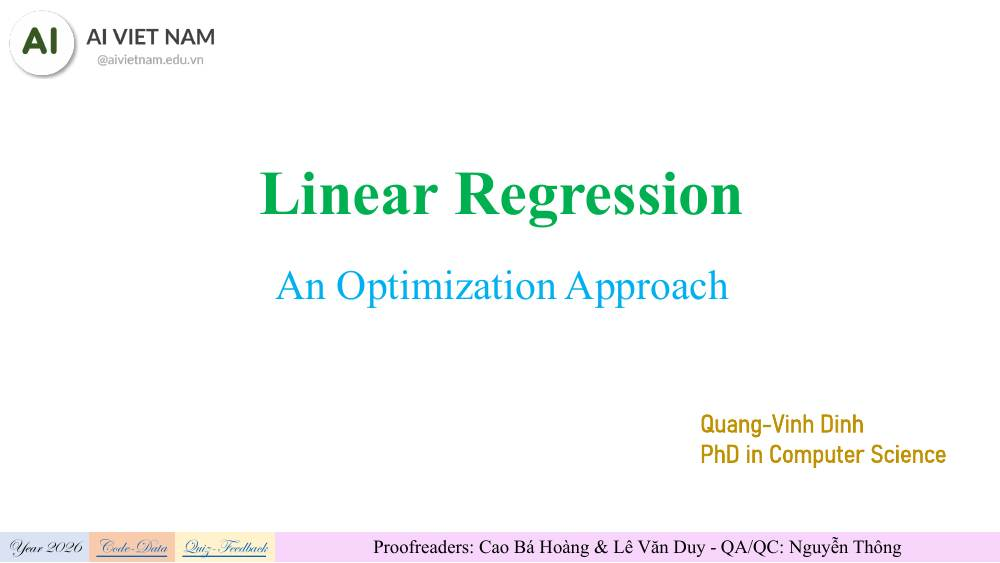<br/><sub><i>Slide trang 1 - Tiêu đề</i></sub></p>

<p align="center">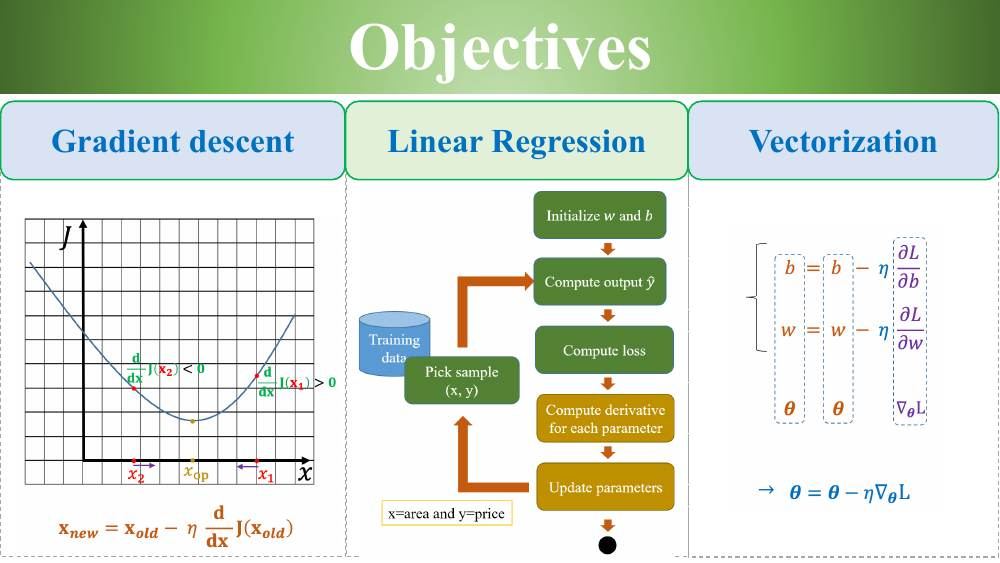<br/><sub><i>Slide trang 2 - Objectives</i></sub></p>

<p align="center">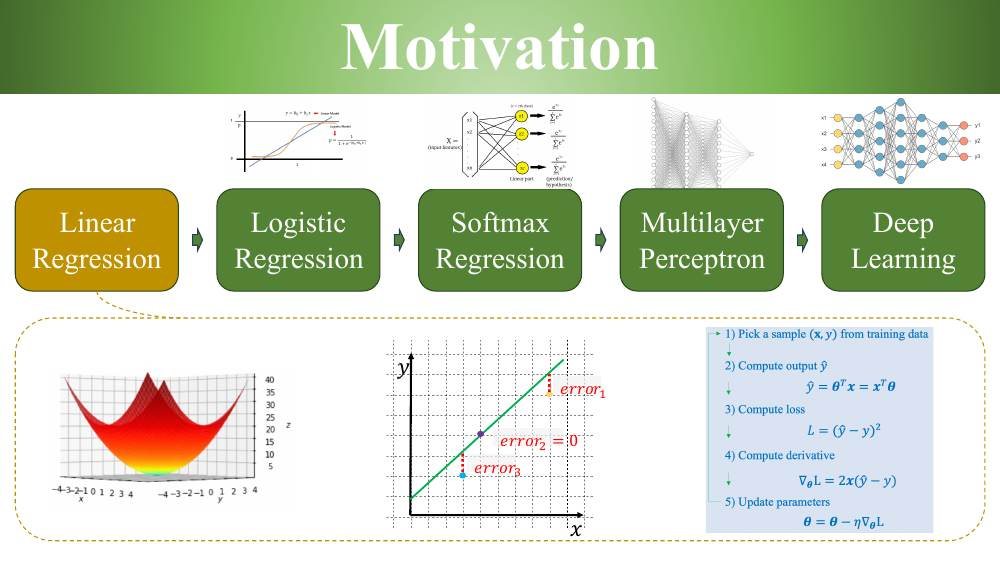<br/><sub><i>Slide trang 3 - Motivation: Linear Regression là nền tảng của Deep Learning</i></sub></p>

<p align="center">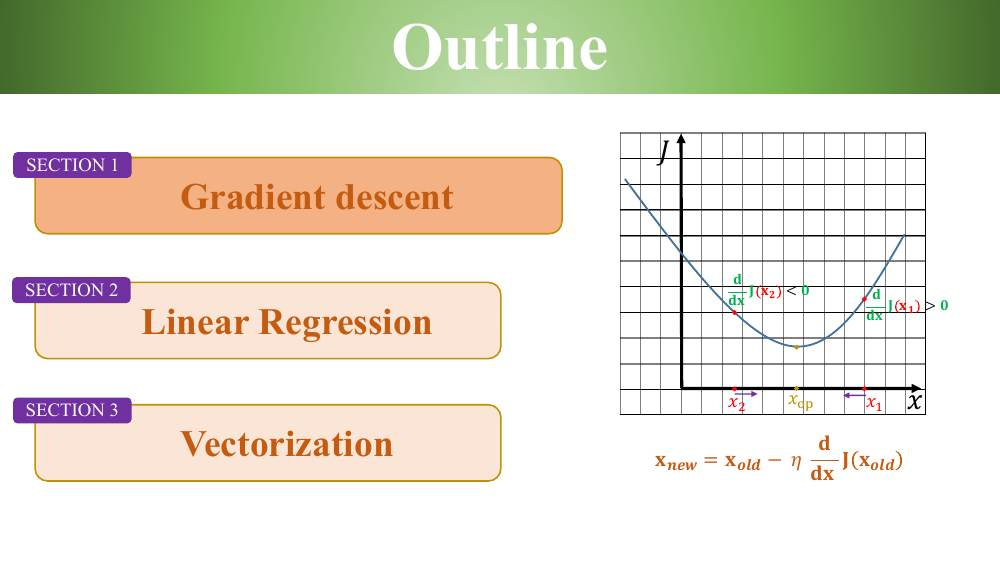<br/><sub><i>Slide trang 4 - Outline</i></sub></p>

## Thiết lập môi trường

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (6, 4),
    "axes.grid": True,
    "grid.alpha": 0.3,
})
np.set_printoptions(precision=4, suppress=True)

---
# SECTION 1 — Gradient descent
## 1.1 Đạo hàm (Derivative)

Đạo hàm cho hàm liên tục là **tỉ số giữa thay đổi theo y và thay đổi theo x** khi $\Delta x \to 0$:

$$\frac{d}{dx}f(x)=\lim_{\Delta x\to 0}\frac{f(x+\Delta x)-f(x)}{\Delta x}$$

$\Delta x$ cần tiến về 0 để đường tiếp tuyến tiến về hàm $f(x)$ trong vùng lân cận tại $x$.

<p align="center">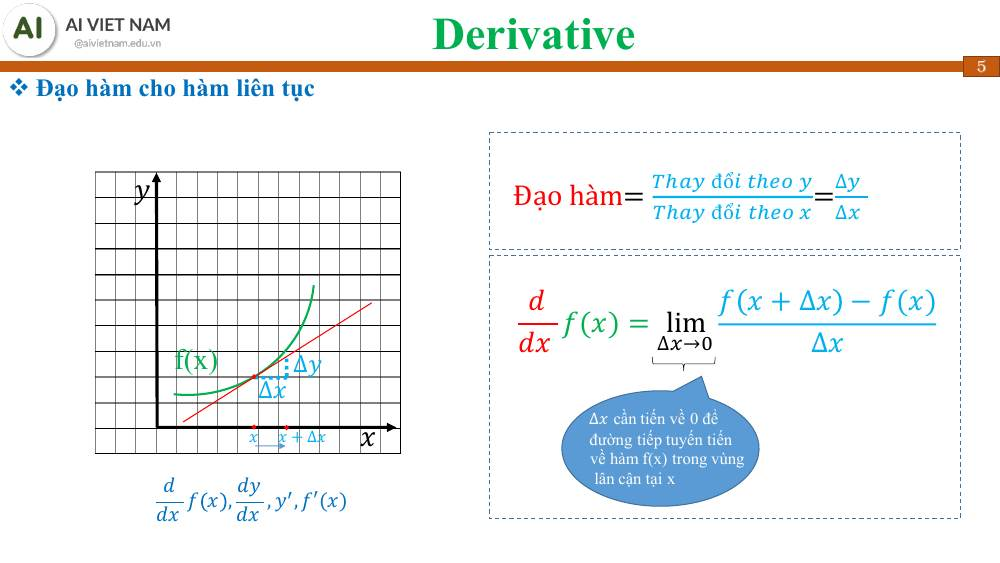<br/><sub><i>Slide trang 5 - Derivative</i></sub></p>

In [ ]:
def numerical_derivative(f, x, dx=1e-6):
    """Xấp xỉ đạo hàm theo định nghĩa: (f(x+dx) - f(x)) / dx"""
    return (f(x + dx) - f(x)) / dx

f = lambda x: x ** 2

for x in [-3, 0, 2, 89]:
    print(f"x = {x:>3} | numeric = {numerical_derivative(f, x):9.4f} | analytic (2x) = {2 * x}")

x =  -3 | numeric =   -6.0000 | analytic (2x) = -6
x =   0 | numeric =    0.0000 | analytic (2x) = 0
x =   2 | numeric =    4.0000 | analytic (2x) = 4
x =  89 | numeric =  178.0000 | analytic (2x) = 178


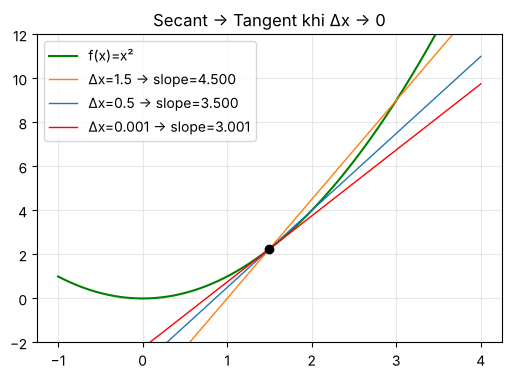

In [ ]:
# Minh họa: secant (Δx lớn) tiến dần về tangent (Δx → 0) tại x0
f = lambda x: x ** 2
x0 = 1.5
xs = np.linspace(-1, 4, 200)

plt.plot(xs, f(xs), "g", label="f(x)=x²")
for dx, c in [(1.5, "tab:orange"), (0.5, "tab:blue"), (1e-3, "red")]:
    slope = (f(x0 + dx) - f(x0)) / dx
    line = f(x0) + slope * (xs - x0)
    plt.plot(xs, line, color=c, lw=1, label=f"Δx={dx:g} → slope={slope:.3f}")
plt.scatter([x0], [f(x0)], color="k", zorder=5)
plt.ylim(-2, 12); plt.legend(); plt.title("Secant → Tangent khi Δx → 0")
plt.show()

## 1.2 Derivative and Optimization — Square function

Với $f(x)=x^2$ thì $\frac{d}{dx}f(x)=2x$; tại $x=89$ đạo hàm là $178$ (đúng như hình trong slide).

<p align="center">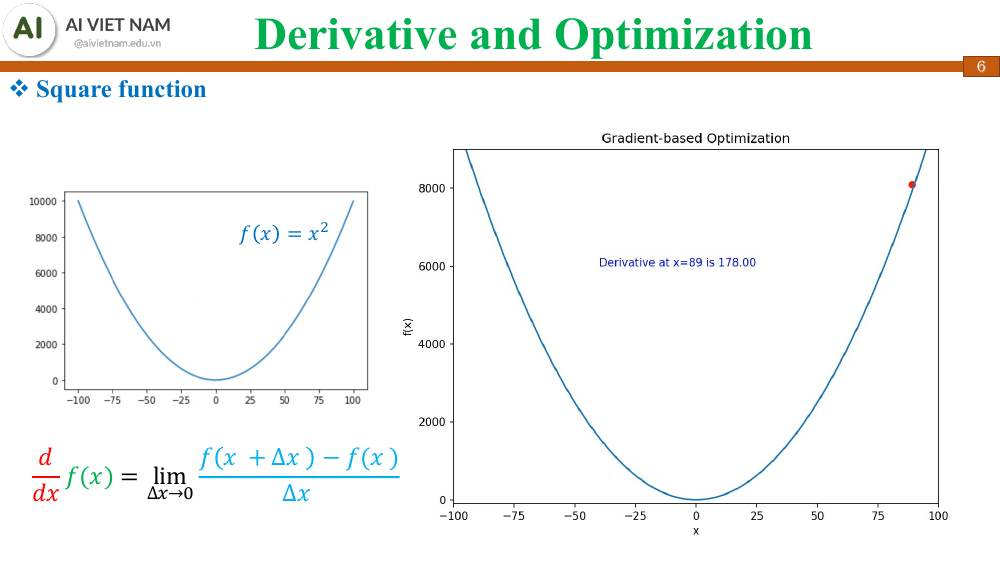<br/><sub><i>Slide trang 6 - Square function</i></sub></p>

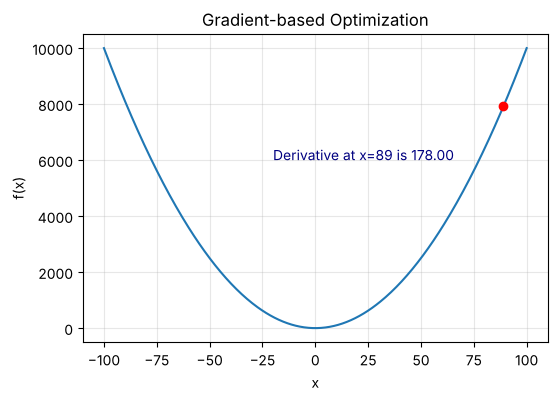

In [ ]:
x = np.linspace(-100, 100, 400)
f = lambda x: x ** 2

plt.plot(x, f(x))
plt.scatter([89], [f(89)], color="red", zorder=5)
plt.annotate(f"Derivative at x=89 is {2 * 89:.2f}", (89, f(89)), xytext=(-20, 6000),
             textcoords="data", color="navy")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.title("Gradient-based Optimization")
plt.show()

## 1.3 Ý tưởng: đi **ngược chiều** đạo hàm

- Nếu $\frac{d}{d\theta}f(\theta) > 0$ → hàm đang tăng theo $\theta$ → **dịch $\theta$ sang trái** để $f$ giảm.
- Nếu $\frac{d}{d\theta}f(\theta) < 0$ → **dịch $\theta$ sang phải**.

Slide minh họa với một hàm có hai điểm cực tiểu. Cứ tiếp tục đi ngược đạo hàm thì $\theta$ sẽ rơi vào một điểm cực tiểu.

<p align="center">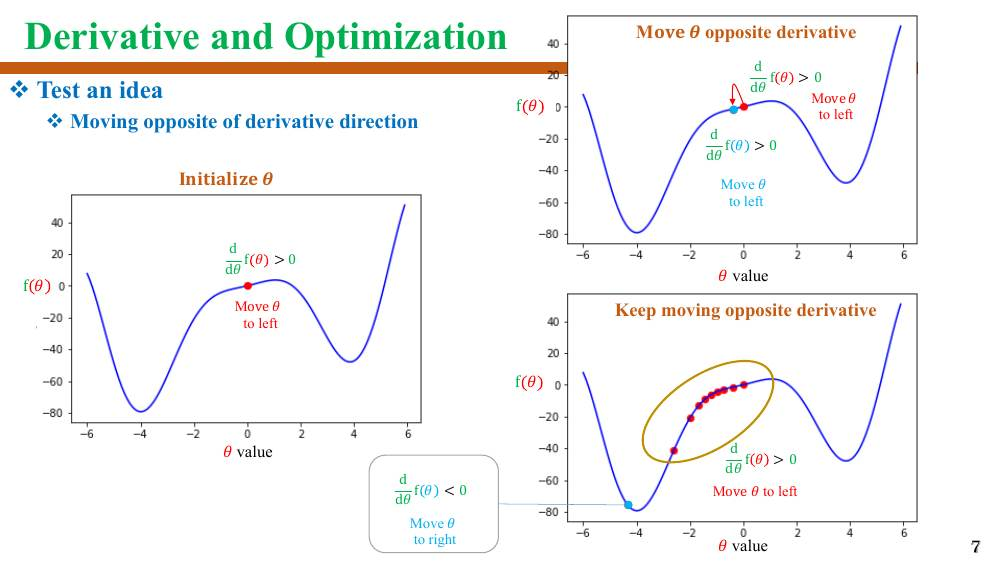<br/><sub><i>Slide trang 7 - Test an idea: moving opposite of derivative direction</i></sub></p>

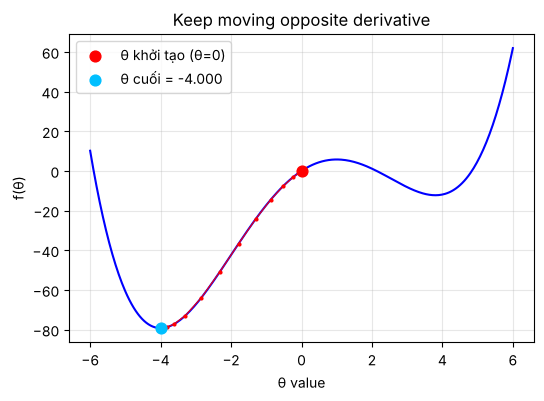

f'(0) = 11.703999999999999 > 0  → dịch sang trái


In [ ]:
# Hàm có 2 cực tiểu (dạng giống slide; đây là hàm minh họa do notebook tự định nghĩa)
k = 0.77
f_nc  = lambda t: k * (t**4 / 4 - 0.8 * t**3 / 3 - 7.7 * t**2 + 15.2 * t)
df_nc = lambda t: k * (t**3 - 0.8 * t**2 - 15.4 * t + 15.2)

theta = 0.0
lr = 0.02
path = [theta]
for _ in range(100):
    theta = theta - lr * df_nc(theta)      # đi NGƯỢC chiều đạo hàm
    path.append(theta)
path = np.array(path)

t = np.linspace(-6, 6, 400)
plt.plot(t, f_nc(t), "b")
plt.plot(path, f_nc(path), "r.-", ms=4, lw=0.8)
plt.scatter([path[0]], [f_nc(path[0])], c="red", s=60, zorder=5, label="θ khởi tạo (θ=0)")
plt.scatter([path[-1]], [f_nc(path[-1])], c="deepskyblue", s=60, zorder=5, label=f"θ cuối = {path[-1]:.3f}")
plt.xlabel("θ value"); plt.ylabel("f(θ)"); plt.legend(); plt.title("Keep moving opposite derivative")
plt.show()
print("f'(0) =", df_nc(0.0), "> 0  → dịch sang trái")

## 1.4 Gradient descent

$$x_{new}=x_{old}-\eta\,\frac{d}{dx}f(x_{old})$$

- $\frac{d}{dx}f(x_{old})$: đạo hàm tại $x_{old}$
- $\eta$: **learning rate** (bước nhảy)

<p align="center">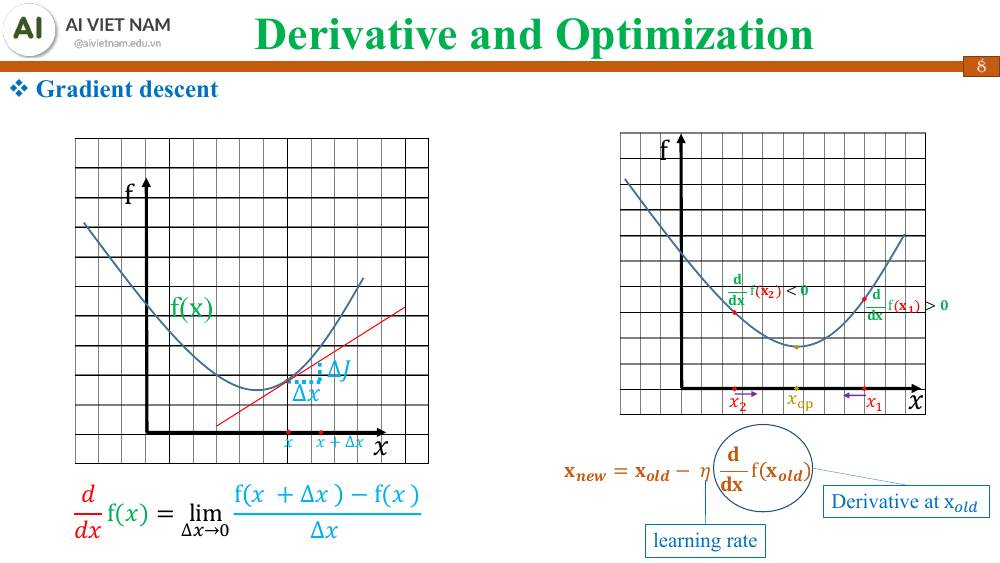<br/><sub><i>Slide trang 8 - Gradient descent</i></sub></p>

In [ ]:
def gradient_descent(df, x0, lr, n_steps):
    """Gradient descent 1D. Trả về toàn bộ quỹ đạo [x0, x1, ..., x_n]."""
    xs = [x0]
    x = x0
    for _ in range(n_steps):
        x = x - lr * df(x)
        xs.append(x)
    return np.array(xs)

---
## Observation 1 — Tối ưu hàm một biến $f(x)=x^2$

Quy trình: Initialize $x$ → Compute derivative at $x$ → Move $x$ opposite of $dx$ → lặp lại.

$$x_t = x_{t-1}-\eta f'(x_{t-1})$$

<p align="center">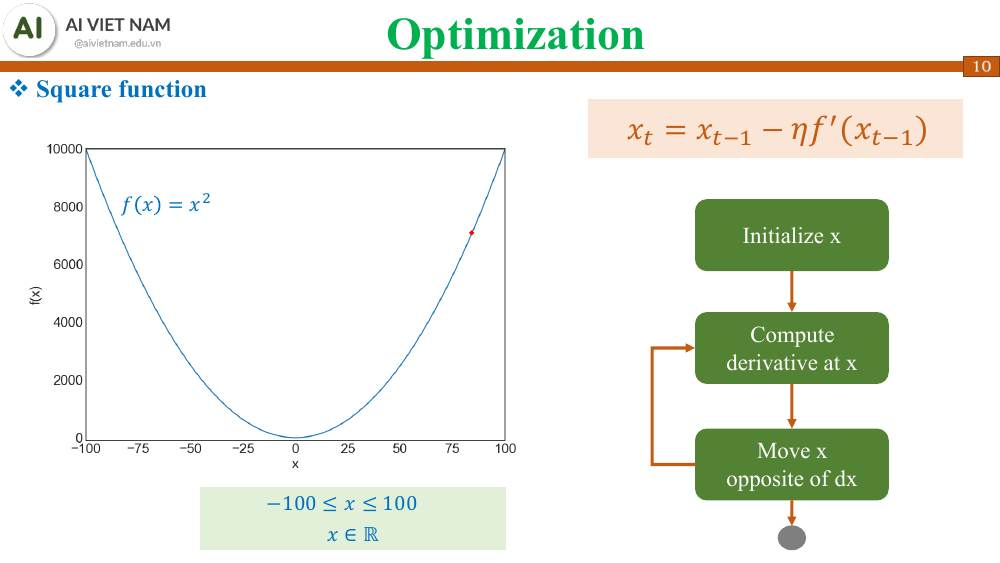<br/><sub><i>Slide trang 10 - Quy trình tối ưu</i></sub></p>

<p align="center">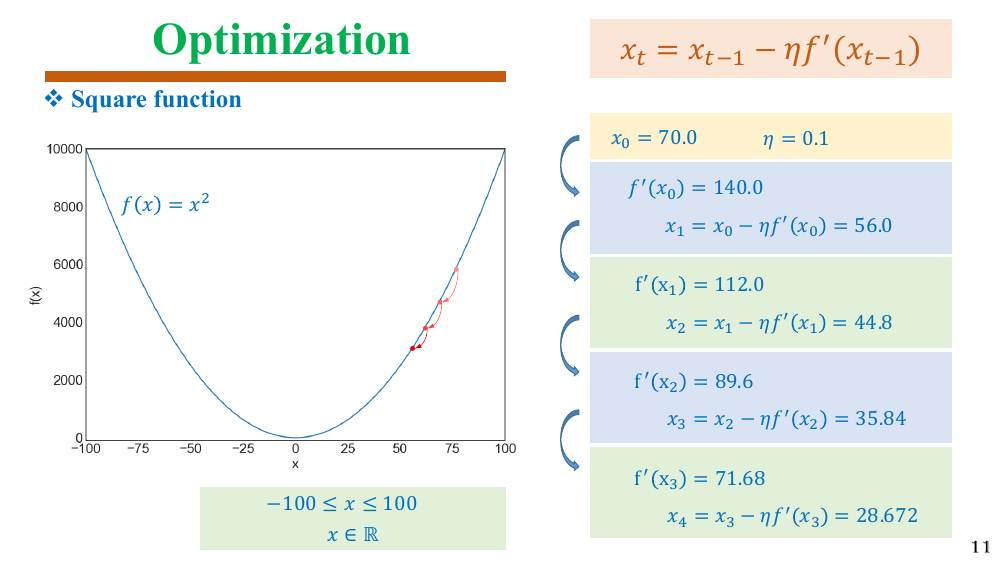<br/><sub><i>Slide trang 11 - x0 = 70.0, η = 0.1</i></sub></p>

In [ ]:
df = lambda x: 2 * x                 # f(x) = x²  →  f'(x) = 2x
x0, lr = 70.0, 0.1

x = x0
print(f"x0 = {x0}  η = {lr}")
for t in range(4):
    g = df(x)
    x_new = x - lr * g
    print(f"f'(x{t}) = {g:7.3f}  →  x{t+1} = x{t} - η·f'(x{t}) = {x_new:.3f}")
    x = x_new

x0 = 70.0  η = 0.1
f'(x0) = 140.000  →  x1 = x0 - η·f'(x0) = 56.000
f'(x1) = 112.000  →  x2 = x1 - η·f'(x1) = 44.800
f'(x2) =  89.600  →  x3 = x2 - η·f'(x2) = 35.840
f'(x3) =  71.680  →  x4 = x3 - η·f'(x3) = 28.672


Chạy tiếp nhiều bước: $x_t = 0.8^t\,x_0$ nên $x$ tiến rất nhanh về $0$ (tối ưu thành công).

<p align="center">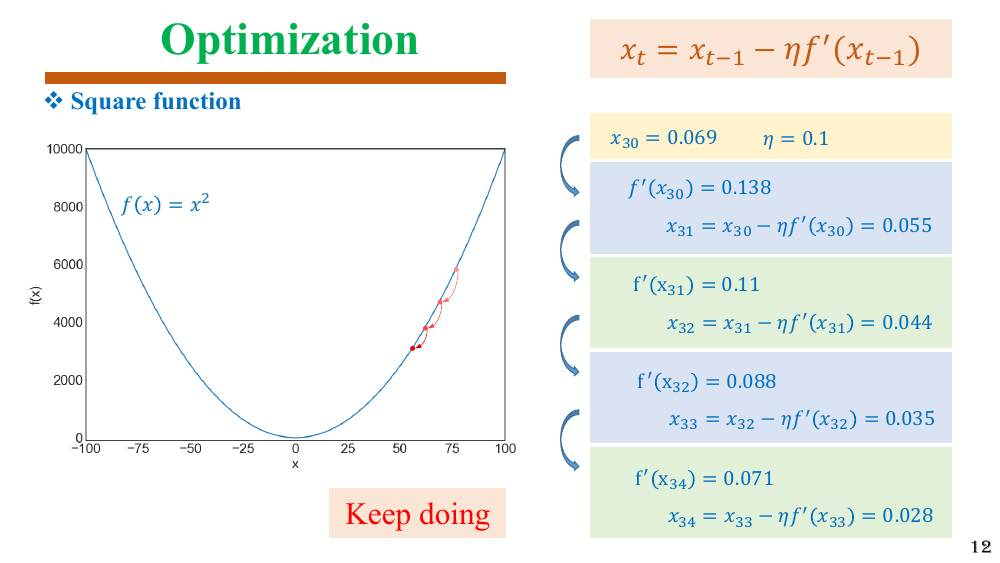<br/><sub><i>Slide trang 12 - Keep doing</i></sub></p>

In [ ]:
traj = gradient_descent(df, x0=70.0, lr=0.1, n_steps=1000)
for t in [30, 31, 32, 33, 34]:
    print(f"x{t:<2} = {traj[t]:.4f}   f'(x{t}) = {df(traj[t]):.4f}")
print("x1000 ≈", traj[-1])

# Mỗi bước f(x_new) <= f(x_old) (loss luôn giảm với η đủ nhỏ)
fvals = traj ** 2
assert np.all(np.diff(fvals) <= 1e-15)
print("f(x_new) <= f(x_old) ở mọi bước ✔")

x30 = 0.0867   f'(x30) = 0.1733
x31 = 0.0693   f'(x31) = 0.1386
x32 = 0.0555   f'(x32) = 0.1109
x33 = 0.0444   f'(x33) = 0.0887
x34 = 0.0355   f'(x34) = 0.0710
x1000 ≈ 8.611623455127804e-96
f(x_new) <= f(x_old) ở mọi bước ✔


> **Ghi chú đối chiếu slide:** slide ghi `x30 = 0.069` nhưng khi tính $70\cdot0.8^t$ thì giá trị này ứng với $t=31$ (nhãn trong slide lệch 1 bước); và slide ghi $x_{1000}\approx10^{-38}$ trong khi tính chính xác bằng float64 ra khoảng $10^{-96}$. Cả hai đều có cùng ý nghĩa: $x$ đã hội tụ về $\approx 0$.

<p align="center">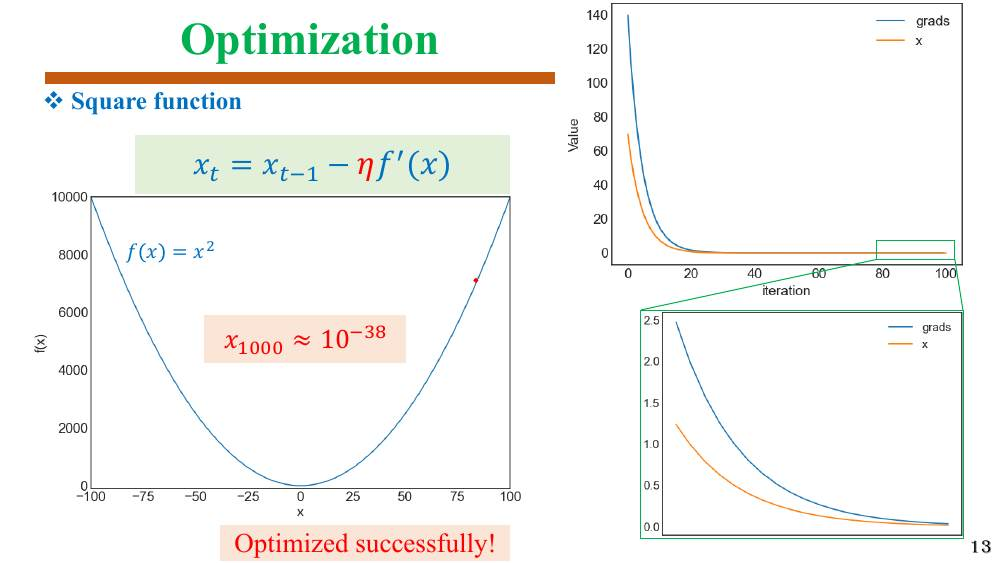<br/><sub><i>Slide trang 13 - Optimized successfully!</i></sub></p>

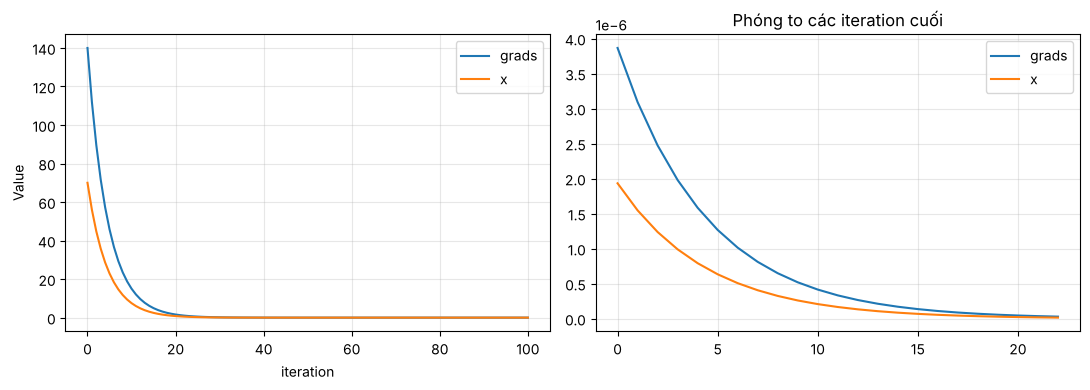

In [ ]:
traj = gradient_descent(df, x0=70.0, lr=0.1, n_steps=100)
grads = df(traj)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(grads, label="grads"); ax[0].plot(traj, label="x")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("Value"); ax[0].legend()

ax[1].plot(grads[78:], label="grads"); ax[1].plot(traj[78:], label="x")
ax[1].set_title("Phóng to các iteration cuối"); ax[1].legend()
plt.tight_layout(); plt.show()

### Ảnh hưởng của learning rate $\eta$

Cùng $x_0=99$ nhưng $\eta$ khác nhau:

| $\eta$ | Hiện tượng |
|---|---|
| 0.1 | hội tụ nhanh |
| 0.001 | quá nhỏ → hội tụ rất chậm |
| 0.8 | lớn nhưng vẫn hội tụ (nhảy qua lại hai bên cực tiểu) |
| 1.1 | quá lớn → **phân kỳ** |

Với $f(x)=x^2$: $x_t = (1-2\eta)\,x_{t-1}$, hội tụ khi $|1-2\eta|<1 \Leftrightarrow 0<\eta<1$.

<p align="center">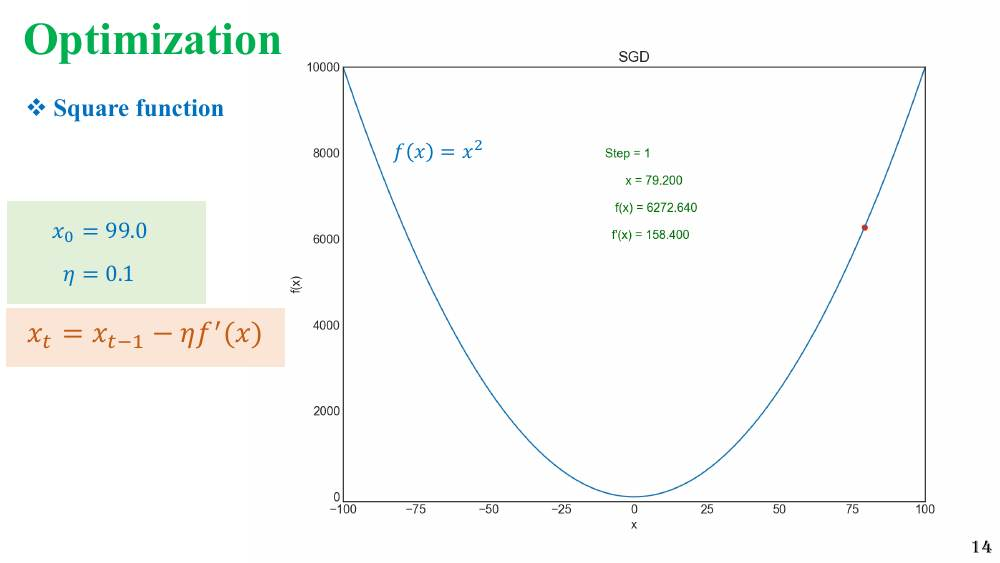<br/><sub><i>Slide trang 14 - η = 0.1</i></sub></p>

<p align="center">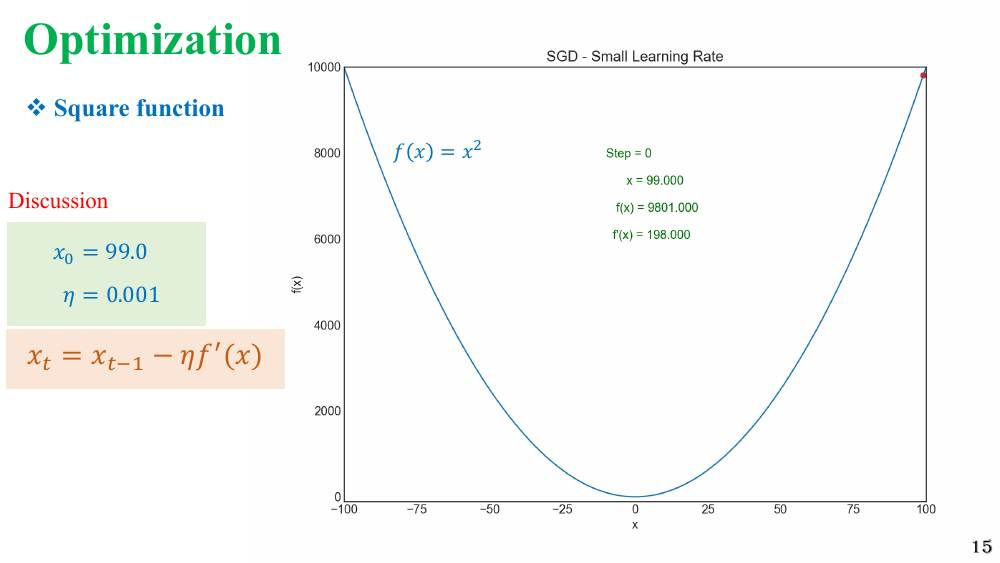<br/><sub><i>Slide trang 15 - Discussion: η = 0.001 (quá nhỏ)</i></sub></p>

<p align="center">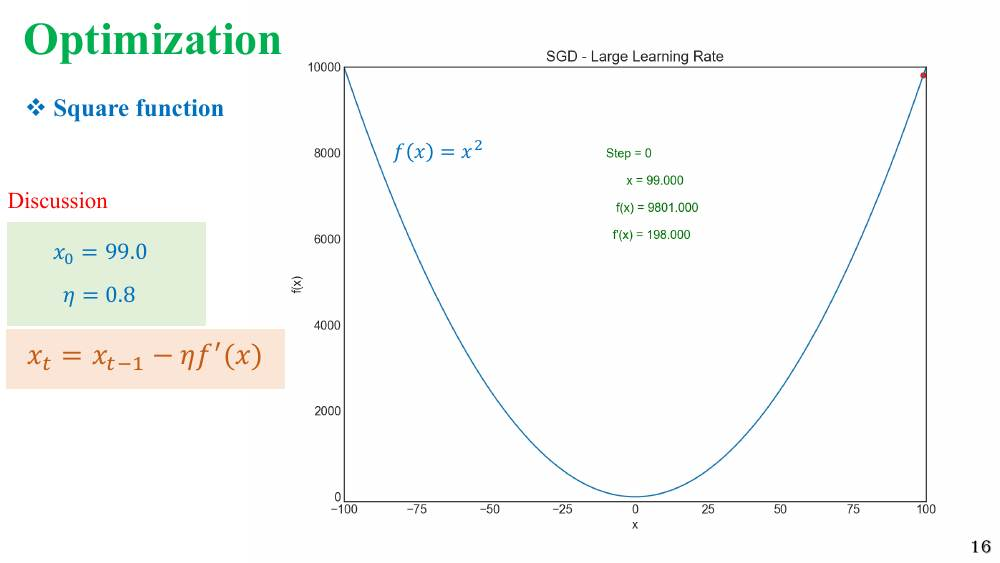<br/><sub><i>Slide trang 16 - Discussion: η = 0.8 (lớn)</i></sub></p>

<p align="center">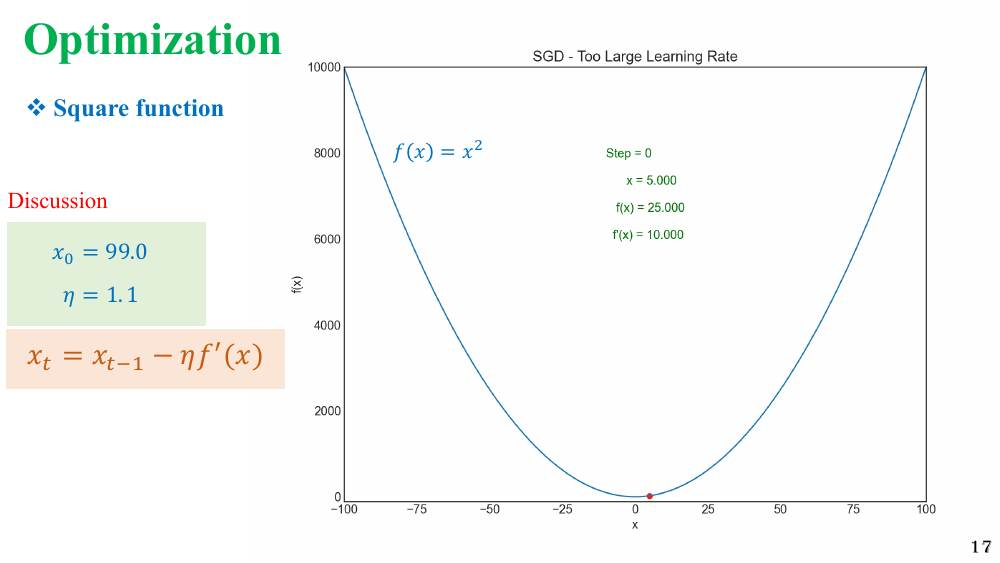<br/><sub><i>Slide trang 17 - Discussion: η = 1.1 (quá lớn)</i></sub></p>

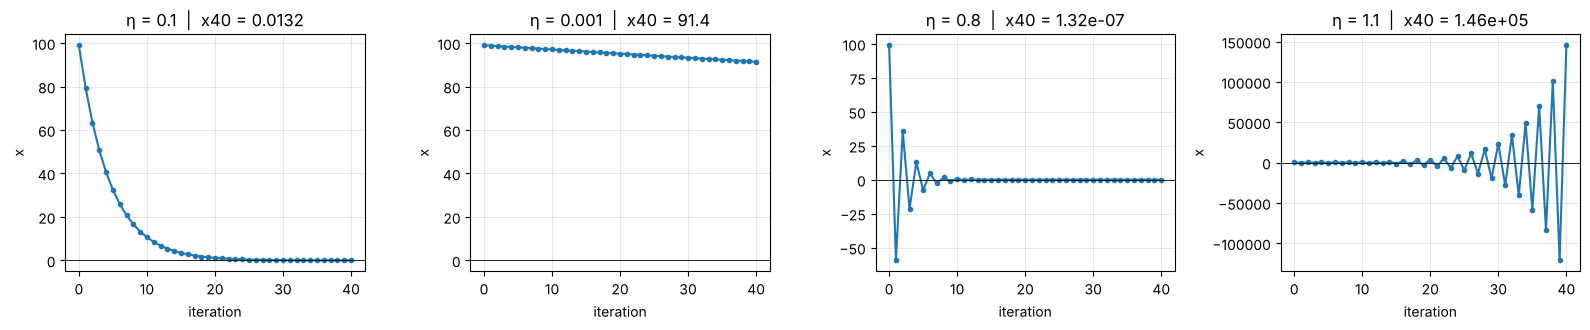

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, eta in zip(axes, [0.1, 0.001, 0.8, 1.1]):
    tr = gradient_descent(df, x0=99.0, lr=eta, n_steps=40)
    ax.plot(tr, "o-", ms=3)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"η = {eta}  |  x40 = {tr[-1]:.3g}")
    ax.set_xlabel("iteration"); ax.set_ylabel("x")
plt.tight_layout(); plt.show()

### Tóm tắt

- Cho hàm $f(x)$, tìm $x_{opt}$ sao cho $f(x_{opt})$ nhỏ nhất.
- Sau mỗi lần cập nhật, $f(x_{new}) \le f(x_{old})$.
- Câu hỏi mở: **$f(x)$ sẽ có ý nghĩa gì** trong bài toán học máy? (→ sẽ là **loss function**).

<p align="center">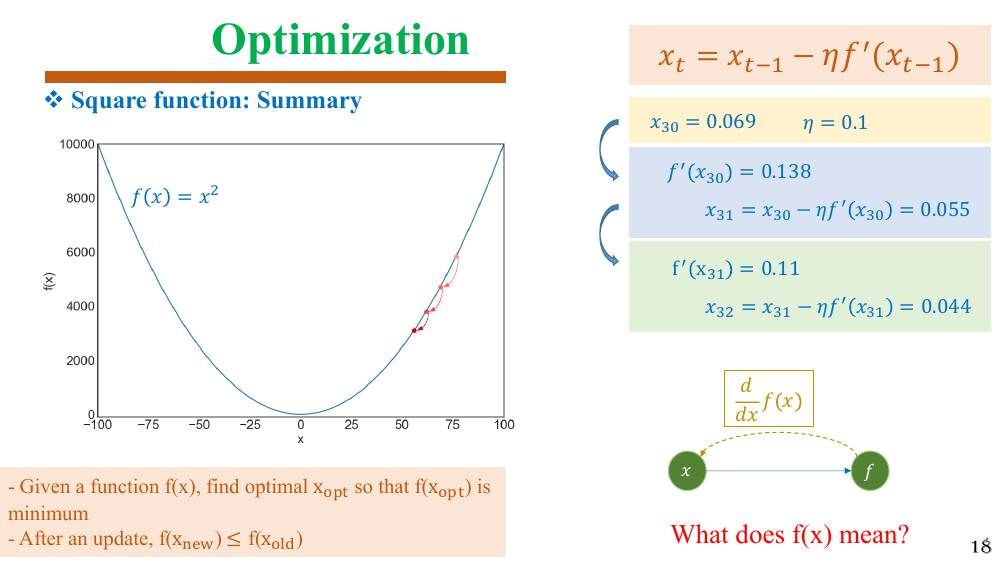<br/><sub><i>Slide trang 18 - Square function: Summary</i></sub></p>

---
## Observation 2 — Tối ưu hàm hai biến $f(x,y)=x^2+y^2$

Với nhiều biến, ta dùng **đạo hàm riêng** cho từng biến:

$$x = x-\eta\frac{\partial f(x,y)}{\partial x},\qquad y = y-\eta\frac{\partial f(x,y)}{\partial y}$$

<p align="center">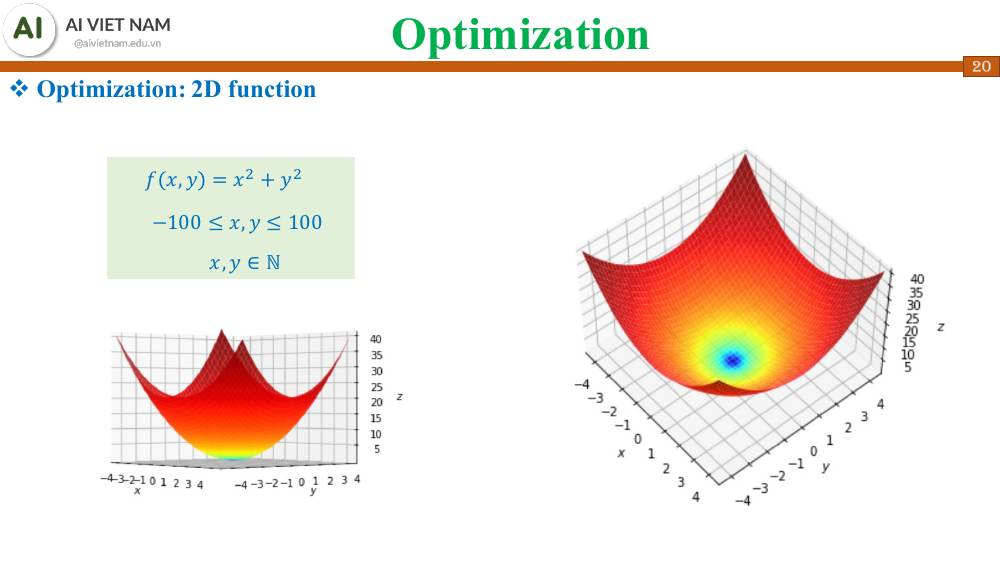<br/><sub><i>Slide trang 20 - Optimization: 2D function</i></sub></p>

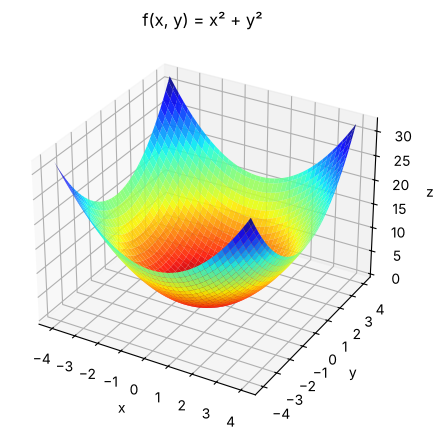

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

X, Y = np.meshgrid(np.linspace(-4, 4, 80), np.linspace(-4, 4, 80))
Z = X**2 + Y**2

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(X, Y, Z, cmap="jet_r", alpha=0.9, linewidth=0)
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
plt.title("f(x, y) = x² + y²")
plt.show()

<p align="center">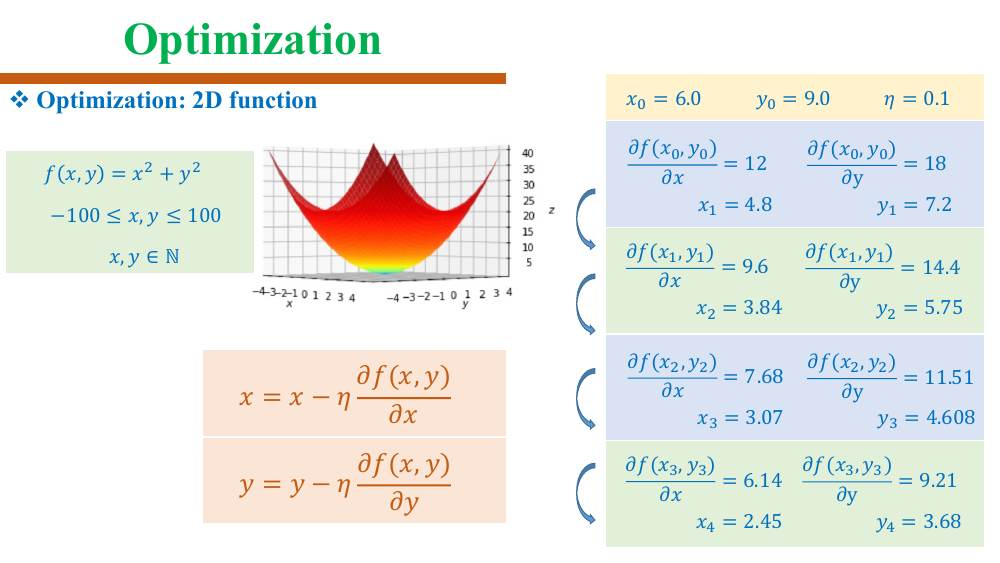<br/><sub><i>Slide trang 21 - x0=6.0, y0=9.0, η=0.1</i></sub></p>

In [ ]:
df_dx = lambda x, y: 2 * x
df_dy = lambda x, y: 2 * y

x, y, lr = 6.0, 9.0, 0.1
print(f"x0 = {x}  y0 = {y}  η = {lr}")
for t in range(4):
    gx, gy = df_dx(x, y), df_dy(x, y)
    x, y = x - lr * gx, y - lr * gy
    print(f"∂f/∂x = {gx:6.2f}  ∂f/∂y = {gy:6.2f}   →  x{t+1} = {x:.3f}  y{t+1} = {y:.3f}")

x0 = 6.0  y0 = 9.0  η = 0.1
∂f/∂x =  12.00  ∂f/∂y =  18.00   →  x1 = 4.800  y1 = 7.200
∂f/∂x =   9.60  ∂f/∂y =  14.40   →  x2 = 3.840  y2 = 5.760
∂f/∂x =   7.68  ∂f/∂y =  11.52   →  x3 = 3.072  y3 = 4.608
∂f/∂x =   6.14  ∂f/∂y =   9.22   →  x4 = 2.458  y4 = 3.686


<p align="center">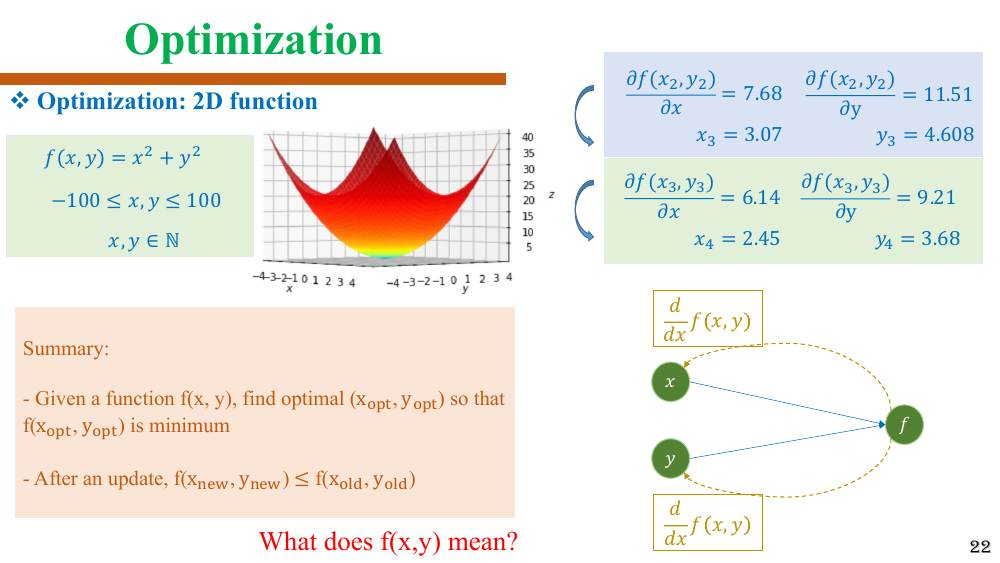<br/><sub><i>Slide trang 22 - Summary: f(x, y)</i></sub></p>

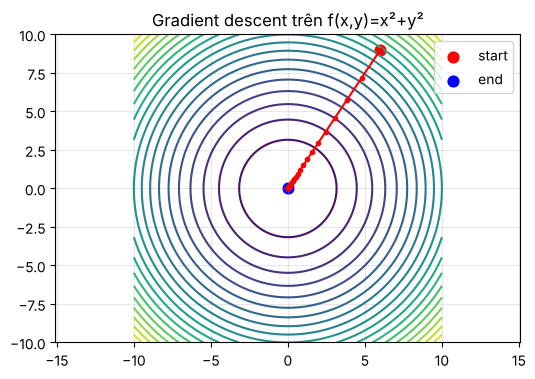

In [ ]:
# Quỹ đạo gradient descent trên contour
x, y, lr = 6.0, 9.0, 0.1
pts = [(x, y)]
for _ in range(30):
    x, y = x - lr * df_dx(x, y), y - lr * df_dy(x, y)
    pts.append((x, y))
pts = np.array(pts)

gx, gy = np.meshgrid(np.linspace(-10, 10, 200), np.linspace(-10, 10, 200))
plt.contour(gx, gy, gx**2 + gy**2, levels=20, cmap="viridis")
plt.plot(pts[:, 0], pts[:, 1], "r.-")
plt.scatter(*pts[0], c="red", s=60, label="start"); plt.scatter(*pts[-1], c="blue", s=60, label="end")
plt.legend(); plt.axis("equal"); plt.title("Gradient descent trên f(x,y)=x²+y²")
plt.show()

---
## Observation 3 — Hàm hợp (composite function) & chain rule

Cho $f(x)=2x-1$ và $g(f)=(f-3)^2$. Hàm hợp $g(f(x))$ có đạo hàm theo chain rule:

$$\frac{d}{dx}g(f(x))=\left[\frac{d}{df}g(f)\right]*\left[\frac{d}{dx}f(x)\right]$$

Tính toán:

$$f'(x)=2,\quad g'(f)=2(f-3)\;\Rightarrow\;\frac{dg}{dx}=\frac{dg}{df}\frac{df}{dx}=2(f-3)\cdot 2=4(2x-1-3)=8x-16$$

<p align="center">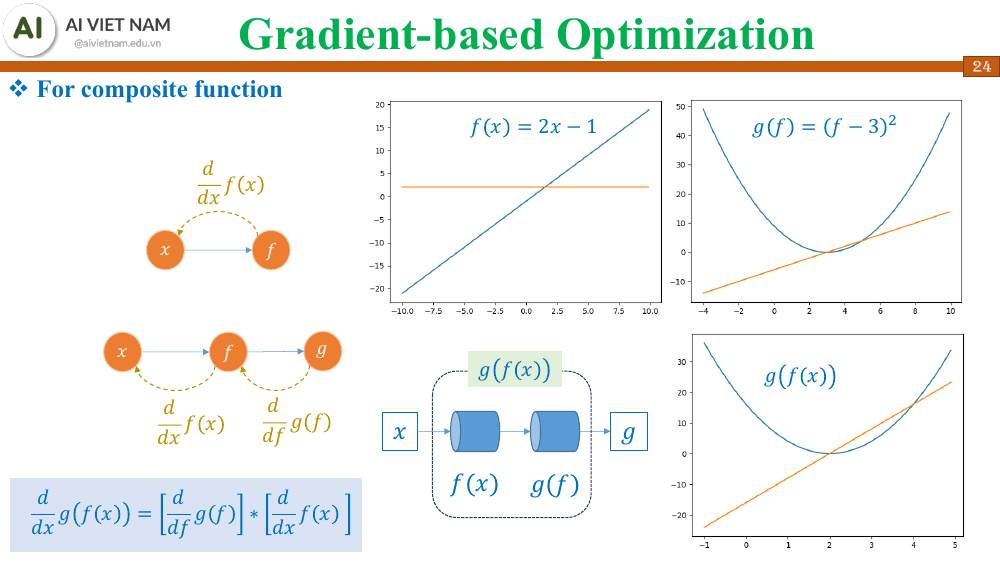<br/><sub><i>Slide trang 24 - For composite function</i></sub></p>

<p align="center">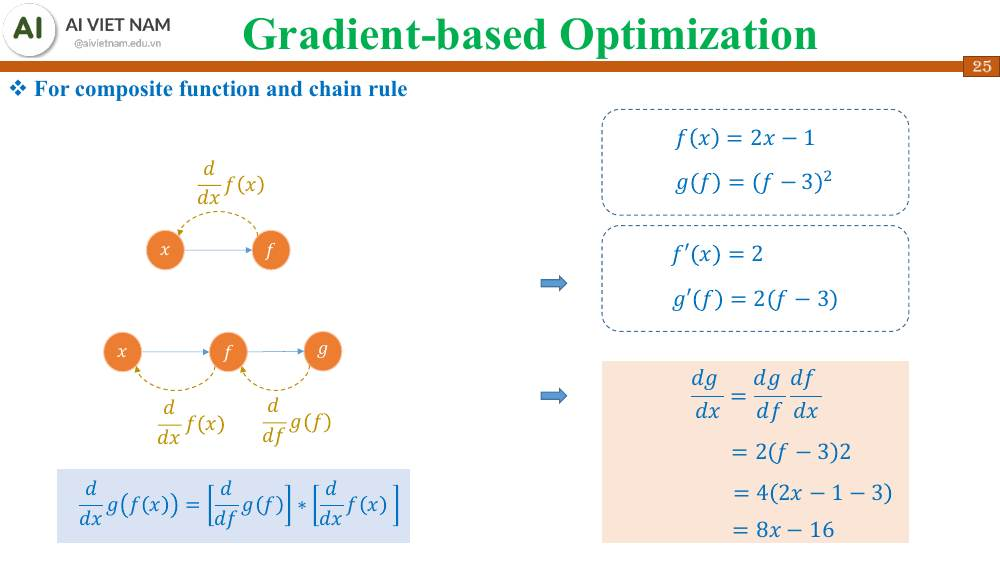<br/><sub><i>Slide trang 25 - For composite function and chain rule</i></sub></p>

In [ ]:
def fx(x):
    return 2 * x - 1

def gf(f):
    return (f - 3) ** 2

def dg_dx(x):
    return 8 * x - 16

# Kiểm tra chain rule bằng đạo hàm số
for x in [-1.0, 2.0, 4.0]:
    num = (gf(fx(x + 1e-6)) - gf(fx(x))) / 1e-6
    print(f"x={x:>4}: numeric={num:8.3f}  chain rule (8x-16)={dg_dx(x)}")

x=-1.0: numeric= -24.000  chain rule (8x-16)=-24.0
x= 2.0: numeric=   0.000  chain rule (8x-16)=0.0
x= 4.0: numeric=  16.000  chain rule (8x-16)=16.0


<p align="center">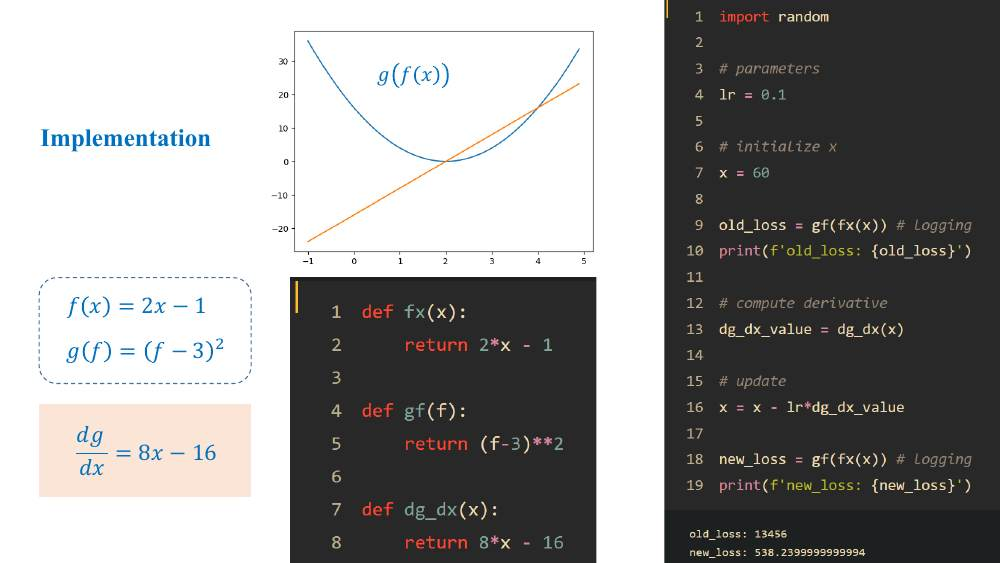<br/><sub><i>Slide trang 26 - Implementation (một bước cập nhật)</i></sub></p>

In [ ]:
# Một bước cập nhật, với logging loss như trong slide
lr = 0.1
x = 60

old_loss = gf(fx(x))
print(f"old_loss: {old_loss}")

dg_dx_value = dg_dx(x)
x = x - lr * dg_dx_value

new_loss = gf(fx(x))
print(f"new_loss: {new_loss}")

old_loss: 13456
new_loss: 538.2399999999994


<p align="center">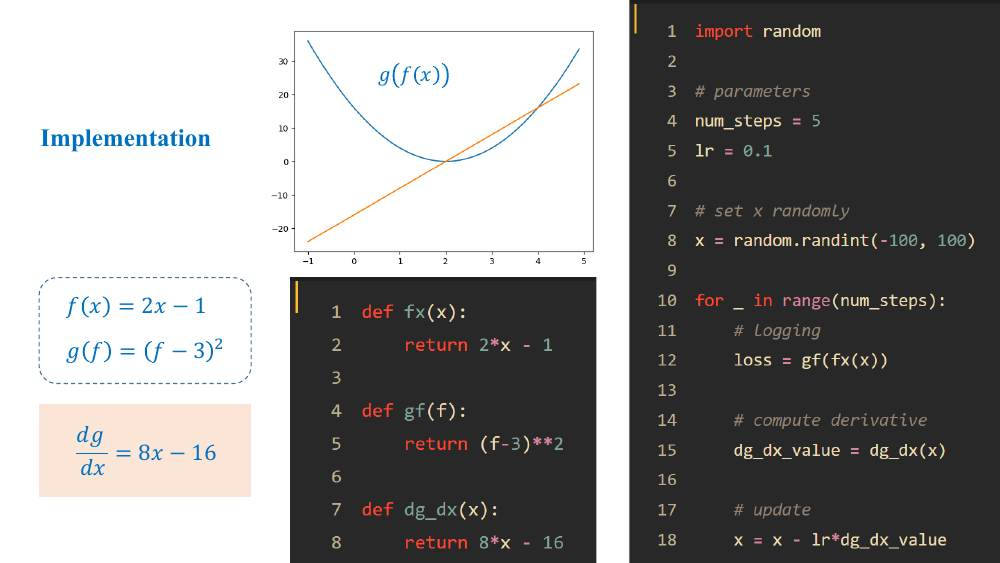<br/><sub><i>Slide trang 27 - Implementation (vòng lặp)</i></sub></p>

In [ ]:
random.seed(0)

# parameters
num_steps = 5
lr = 0.1

# set x randomly
x = random.randint(-100, 100)
print("x khởi tạo =", x)

for _ in range(num_steps):
    # logging
    loss = gf(fx(x))

    # compute derivative
    dg_dx_value = dg_dx(x)

    # update
    x = x - lr * dg_dx_value
    print(f"loss = {loss:10.4f} | dg/dx = {dg_dx_value:9.3f} | x = {x:.4f}")

x khởi tạo = -2
loss =    64.0000 | dg/dx =   -32.000 | x = 1.2000
loss =     2.5600 | dg/dx =    -6.400 | x = 1.8400
loss =     0.1024 | dg/dx =    -1.280 | x = 1.9680
loss =     0.0041 | dg/dx =    -0.256 | x = 1.9936
loss =     0.0002 | dg/dx =    -0.051 | x = 1.9987


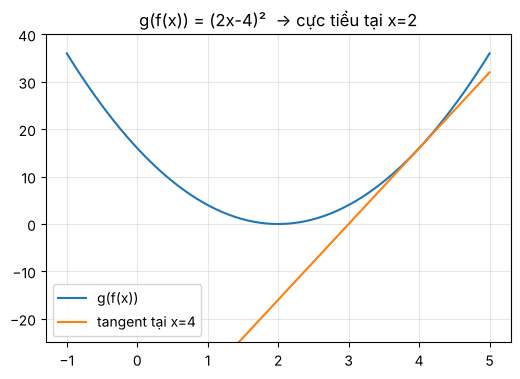

In [ ]:
xs = np.linspace(-1, 5, 200)
plt.plot(xs, gf(fx(xs)), label="g(f(x))")
x0 = 4.0
plt.plot(xs, gf(fx(x0)) + dg_dx(x0) * (xs - x0), label="tangent tại x=4")
plt.ylim(-25, 40); plt.legend(); plt.title("g(f(x)) = (2x-4)²  → cực tiểu tại x=2")
plt.show()

### Tóm tắt

- Cho $g(f(x))$, tìm $x_{opt}$ sao cho $g(f(x_{opt}))$ nhỏ nhất.
- Sau mỗi lần cập nhật, $g(f(x_{new})) \le g(f(x_{old}))$.
- **$g(f(x))$ có nghĩa là gì?** Chính là mô hình: $f$ = đầu ra của mô hình (prediction), $g$ = hàm loss. Đây là bản chất của **backpropagation**.

<p align="center">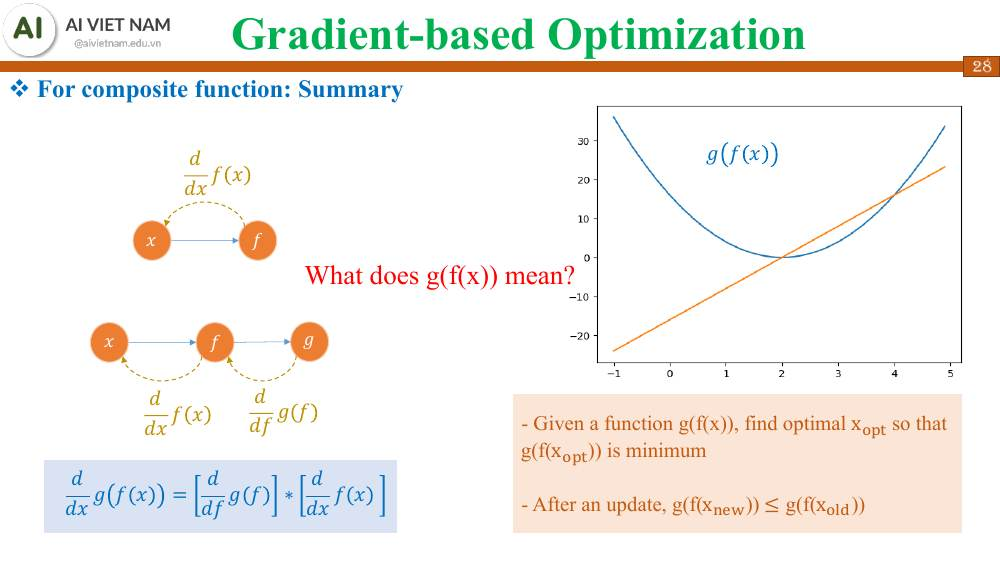<br/><sub><i>Slide trang 28 - For composite function: Summary</i></sub></p>

---
# SECTION 2 — Linear Regression
## 2.1 Giới thiệu

Bài toán: cho các **features** và **label** → dự đoán label cho dữ liệu mới.

- House price data: `area` → `price`
- Advertising data: `TV`, `Radio`, `Newspaper` → `Sales`
- Boston House Price data: 13 features → `medv`

<p align="center">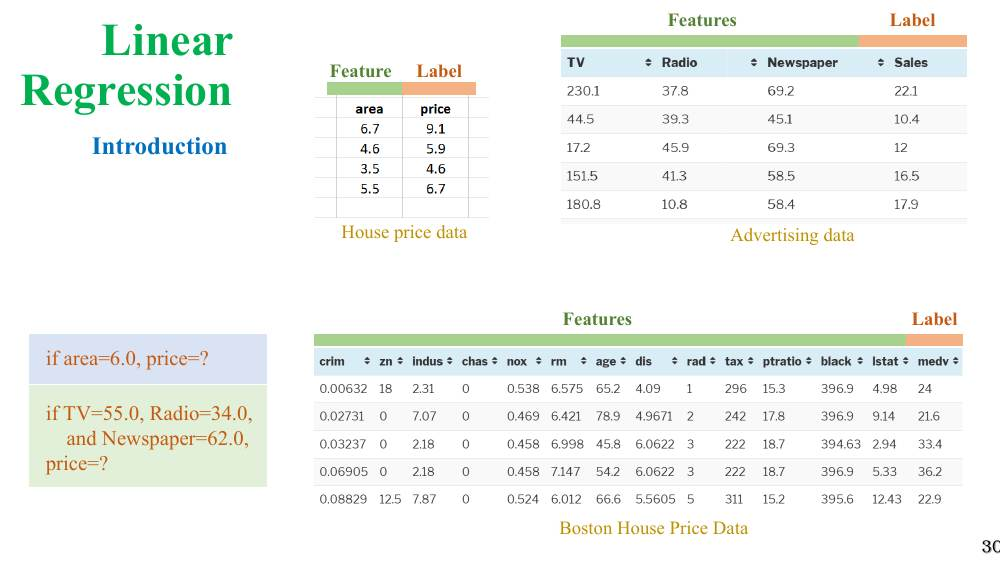<br/><sub><i>Slide trang 31 - Introduction</i></sub></p>

## 2.2 House Price Prediction

Dữ liệu (dùng bộ số xuyên suốt phần còn lại của slide):

| area | price |
|---|---|
| 6.7 | 9.1 |
| 4.6 | 5.9 |
| 3.5 | 4.6 |
| 5.5 | 6.7 |

Mô hình tuyến tính: $\;\text{price}=w*\text{area}+b$. Các cặp $(w,b)$ khác nhau cho ra các đường thẳng khác nhau — **làm sao chọn đường tốt nhất?**

<p align="center">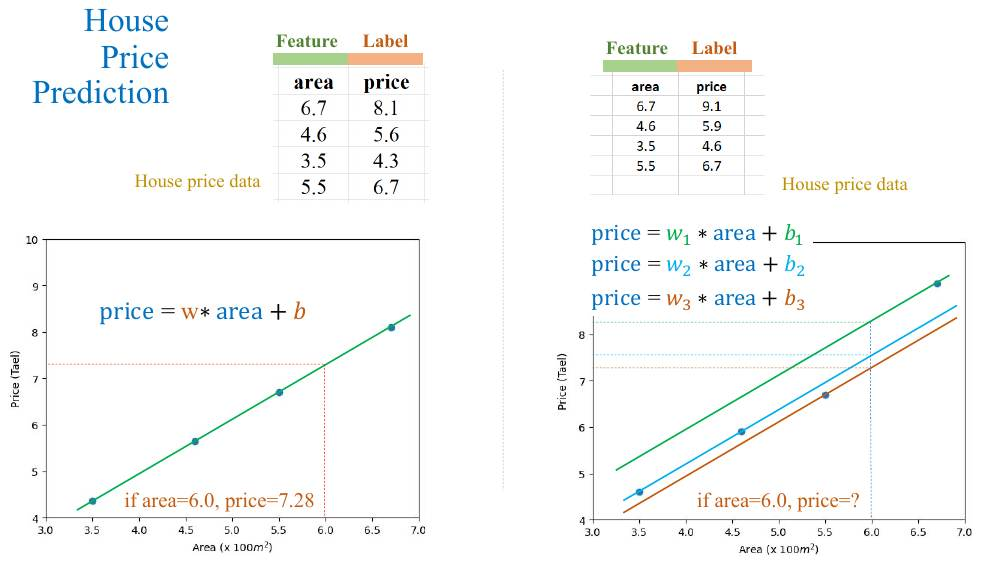<br/><sub><i>Slide trang 32 - House Price Prediction</i></sub></p>

In [ ]:
# Tạo file data.csv (cột 0: area, cột 1: price) giống slide
with open("data.csv", "w") as f:
    f.write("6.7,9.1\n4.6,5.9\n3.5,4.6\n5.5,6.7\n")

data = np.genfromtxt("data.csv", delimiter=",")
areas, prices = data[:, 0], data[:, 1]
N = data.shape[0]
print("areas :", areas)
print("prices:", prices)
print("data_size:", N)

areas : [6.7 4.6 3.5 5.5]
prices: [9.1 5.9 4.6 6.7]
data_size: 4


if area=6.0, price = 7.28


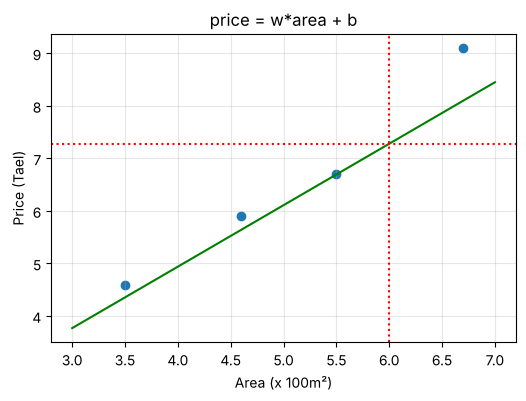

In [ ]:
# Dự đoán giá nhà 6.0 với w=1.17, b=0.26 (đường màu xanh trong slide)
w, b = 1.17, 0.26
print("if area=6.0, price =", round(w * 6.0 + b, 2))

xs = np.linspace(3, 7, 50)
plt.scatter(areas, prices)
plt.plot(xs, w * xs + b, "g")
plt.axvline(6.0, color="r", ls=":"); plt.axhline(w * 6.0 + b, color="r", ls=":")
plt.xlabel("Area (x 100m²)"); plt.ylabel("Price (Tael)"); plt.title("price = w*area + b")
plt.show()

### Error của mô hình

Với mỗi mẫu $i$: $\;error_i=distance(\hat y_i,y_i)$. Ta muốn tìm $w,b$ sao cho

$$error=\frac{1}{N}\sum_i error_i \quad\text{nhỏ nhất}$$

Hỏi: **How?** (làm thế nào để tìm?)

<p align="center">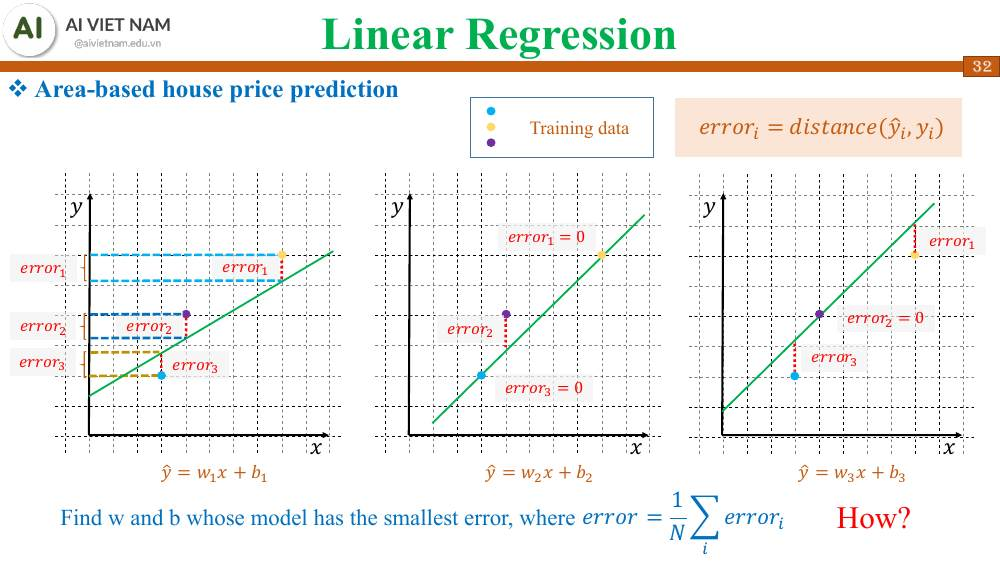<br/><sub><i>Slide trang 33 - Area-based house price prediction</i></sub></p>

### Loss: bình phương sai số

$$\hat y_i = w x_i + b,\qquad L(\hat y_i, y_i)=(\hat y_i-y_i)^2$$

Hai bộ tham số trong slide: $(w,b)=(-0.34,\,0.04)$ → sai số rất lớn; $(w,b)=(1.17,\,0.26)$ → sai số nhỏ.

<p align="center">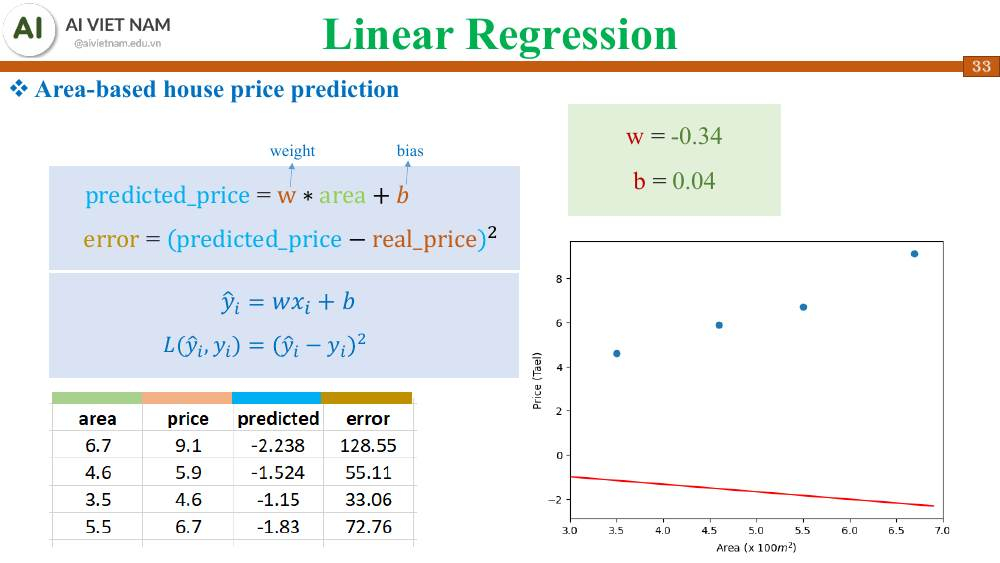<br/><sub><i>Slide trang 34 - w=-0.34, b=0.04</i></sub></p>

<p align="center">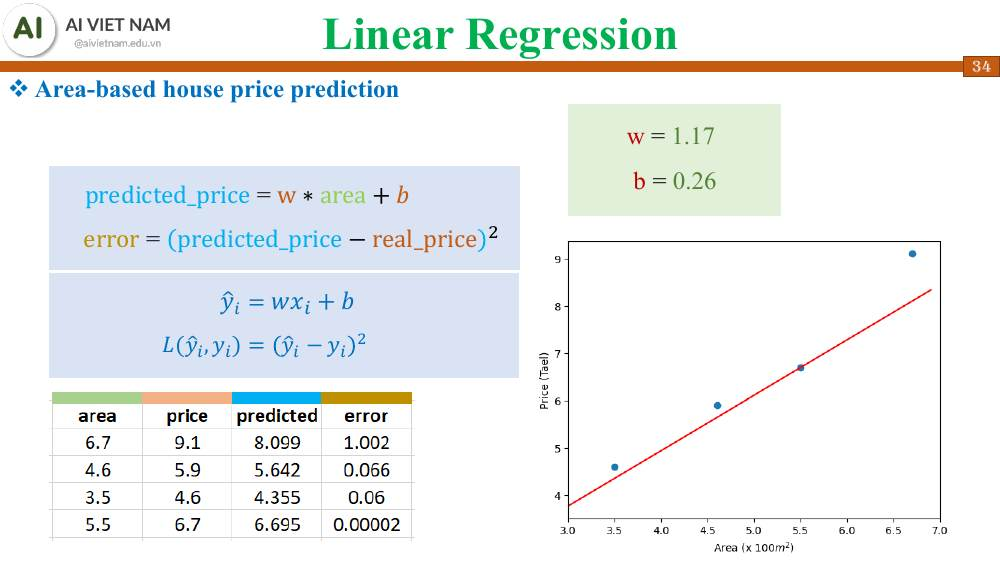<br/><sub><i>Slide trang 35 - w=1.17, b=0.26</i></sub></p>

In [ ]:
def show_table(w, b):
    print(f"w = {w}, b = {b}")
    print(f"{'area':>6} {'price':>7} {'predicted':>10} {'error':>9}")
    for x, y in zip(areas, prices):
        y_hat = w * x + b
        print(f"{x:6.1f} {y:7.1f} {y_hat:10.3f} {(y_hat - y) ** 2:9.5f}")
    print()

show_table(-0.34, 0.04)    # lỗi rất lớn
show_table(1.17, 0.26)     # lỗi nhỏ

w = -0.34, b = 0.04
  area   price  predicted     error
   6.7     9.1     -2.238 128.55024
   4.6     5.9     -1.524  55.11578
   3.5     4.6     -1.150  33.06250
   5.5     6.7     -1.830  72.76090

w = 1.17, b = 0.26
  area   price  predicted     error
   6.7     9.1      8.099   1.00200
   4.6     5.9      5.642   0.06656
   3.5     4.6      4.355   0.06003
   5.5     6.7      6.695   0.00003



<p align="center">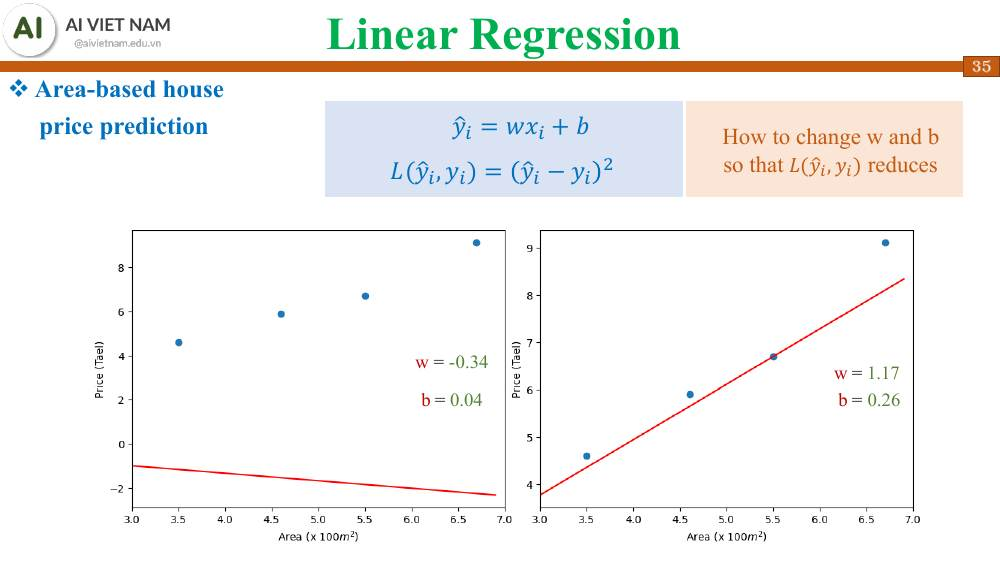<br/><sub><i>Slide trang 36 - Làm sao thay đổi w và b để L(ŷ, y) giảm?</i></sub></p>

## 2.3 Hiểu hàm loss

Cố định $w$ rồi đổi $b$ (hoặc ngược lại), đường cong loss là **một parabol** → có đúng một điểm cực tiểu → có thể dùng **gradient descent**.

<p align="center">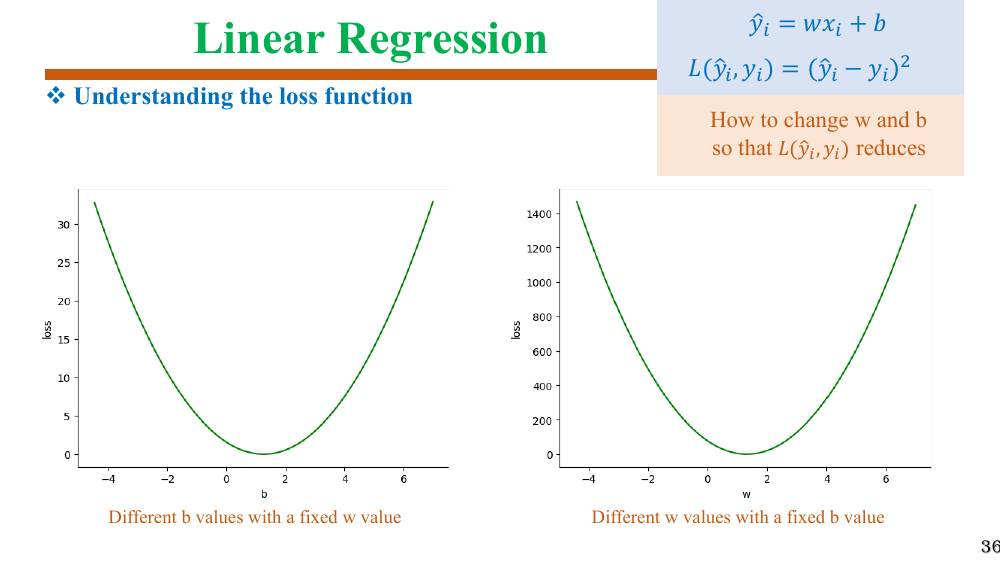<br/><sub><i>Slide trang 37 - Understanding the loss function</i></sub></p>

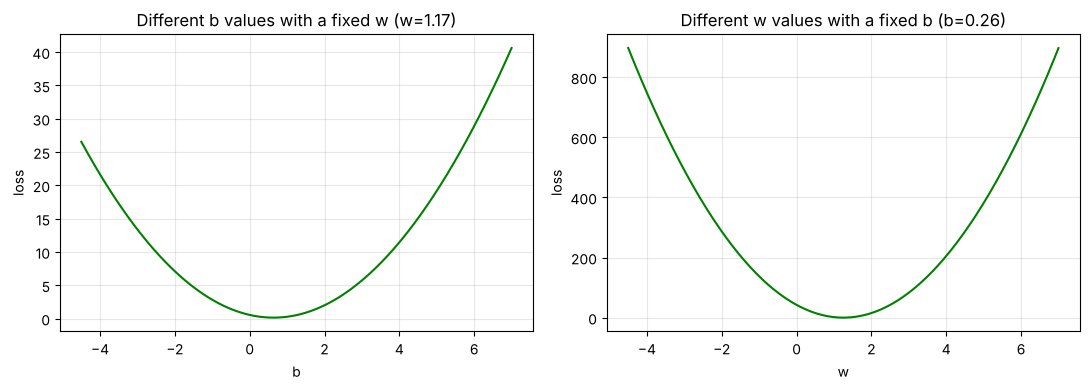

In [ ]:
def mse(w, b):
    return np.mean((w * areas + b - prices) ** 2)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

bs = np.linspace(-4.5, 7, 200)
ax[0].plot(bs, [mse(1.17, b) for b in bs], "g")
ax[0].set_xlabel("b"); ax[0].set_ylabel("loss"); ax[0].set_title("Different b values with a fixed w (w=1.17)")

ws = np.linspace(-4.5, 7, 200)
ax[1].plot(ws, [mse(w, 0.26) for w in ws], "g")
ax[1].set_xlabel("w"); ax[1].set_ylabel("loss"); ax[1].set_title("Different w values with a fixed b (b=0.26)")
plt.tight_layout(); plt.show()

## 2.4 Công thức Linear Regression + đạo hàm

**Linear equation:** $\hat y = wx+b$ ($\hat y$: giá trị dự đoán, $w,b$: tham số, $x$: input feature)

**Loss (squared loss):** $L(\hat y,y)=(\hat y-y)^2$

**Đạo hàm bằng chain rule:**

$$\frac{\partial L}{\partial w}=\frac{\partial L}{\partial \hat y}\frac{\partial \hat y}{\partial w}=2x(\hat y-y),\qquad
\frac{\partial L}{\partial b}=\frac{\partial L}{\partial \hat y}\frac{\partial \hat y}{\partial b}=2(\hat y-y)$$

**Cập nhật tham số:**

$$w=w-\eta\frac{\partial L}{\partial w},\qquad b=b-\eta\frac{\partial L}{\partial b}$$

<p align="center">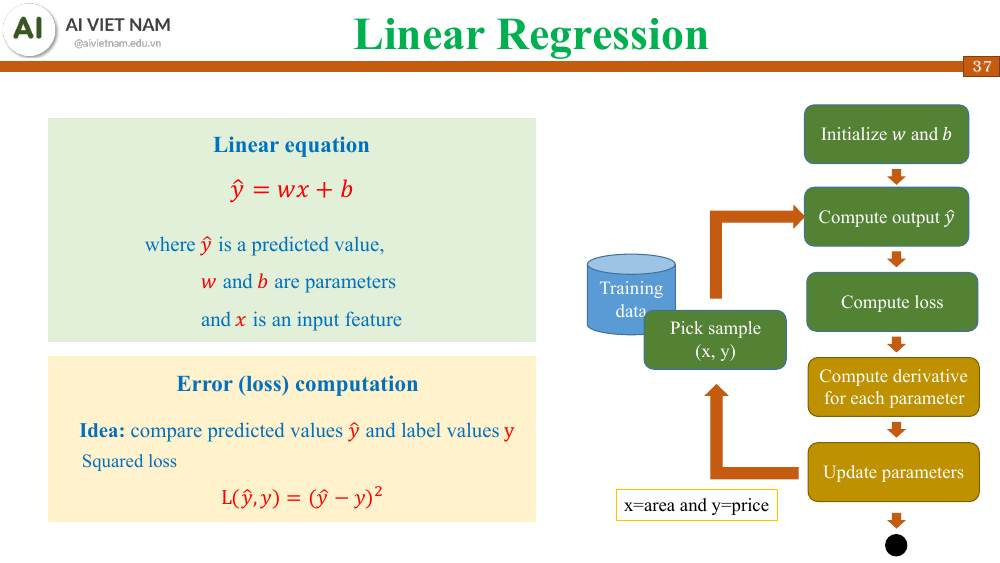<br/><sub><i>Slide trang 38 - Linear equation & Error (loss) computation</i></sub></p>

<p align="center">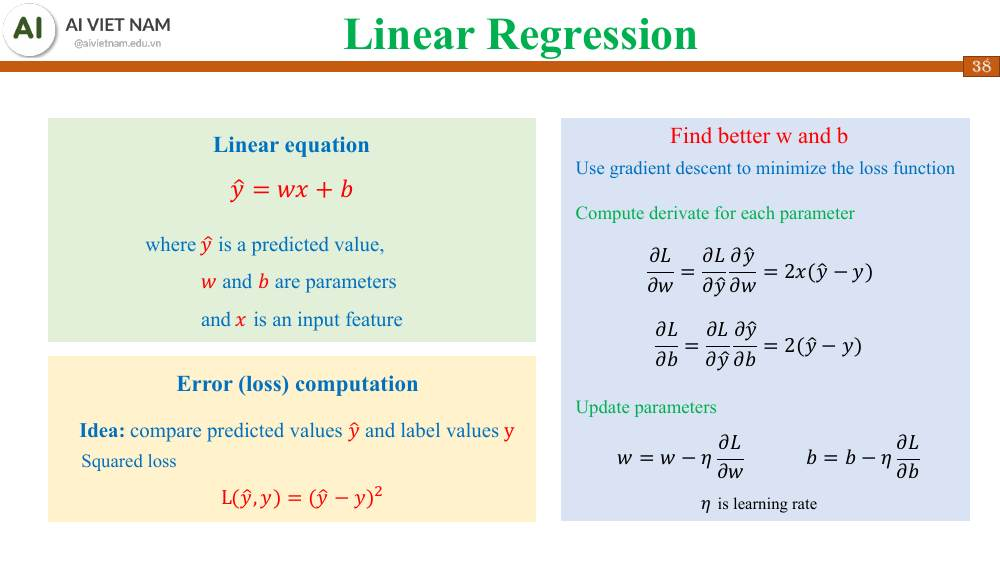<br/><sub><i>Slide trang 39 - Find better w and b</i></sub></p>

<p align="center">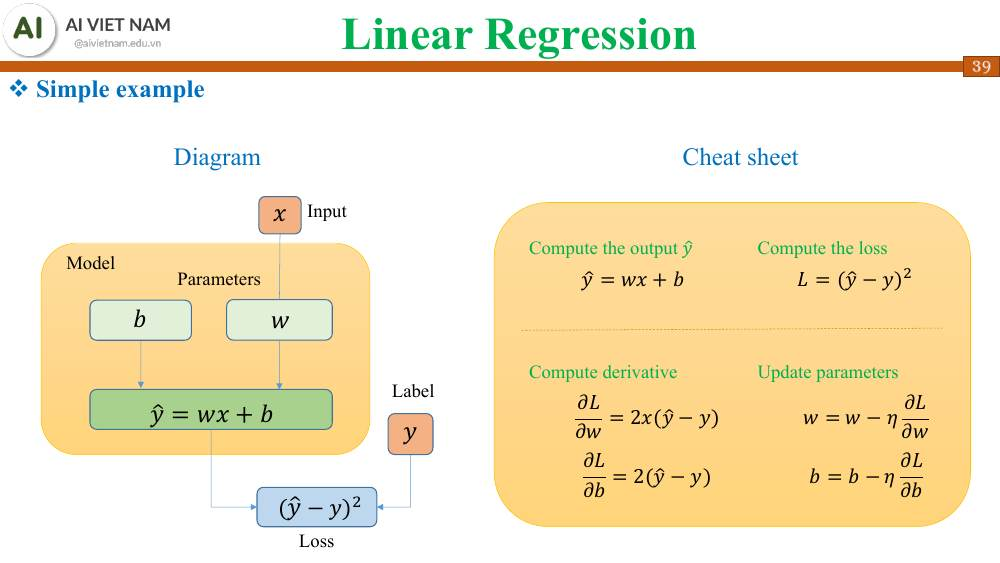<br/><sub><i>Slide trang 40 - Cheat sheet</i></sub></p>

### Ví dụ chạy tay một bước (mẫu $x=6.7,\;y=9.1$, khởi tạo $b=0.04,\;w=-0.34$, $\eta=0.01$)

**① Forward propagation**

<p align="center">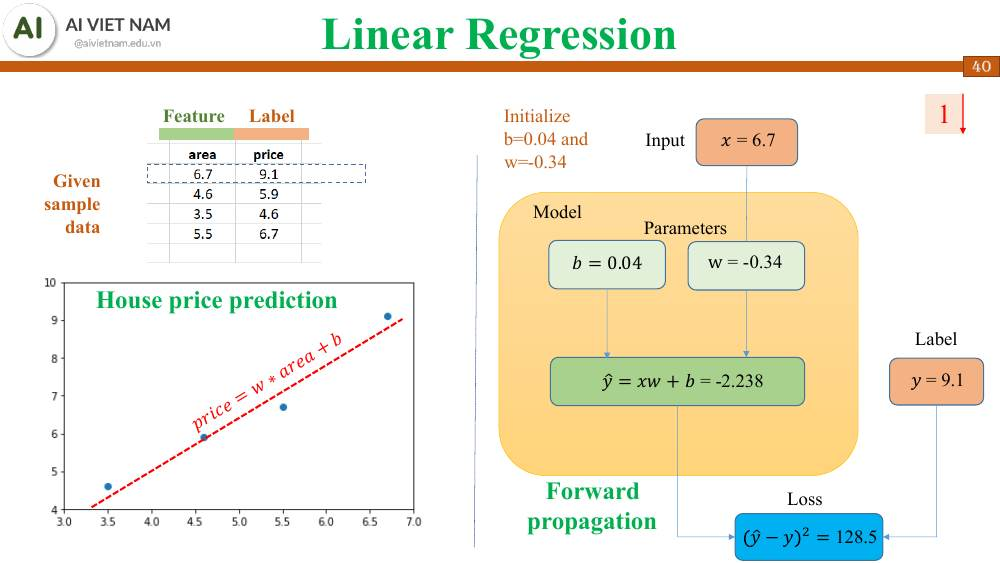<br/><sub><i>Slide trang 41 - Forward propagation</i></sub></p>

In [ ]:
x, y = 6.7, 9.1
b, w = 0.04, -0.34
lr = 0.01

y_hat = x * w + b
loss = (y_hat - y) ** 2
print(f"y_hat = {y_hat:.3f}   loss = {loss:.2f}")      # -2.238 ; 128.5

y_hat = -2.238   loss = 128.55


**② Backpropagation** — tính đạo hàm rồi cập nhật tham số

<p align="center">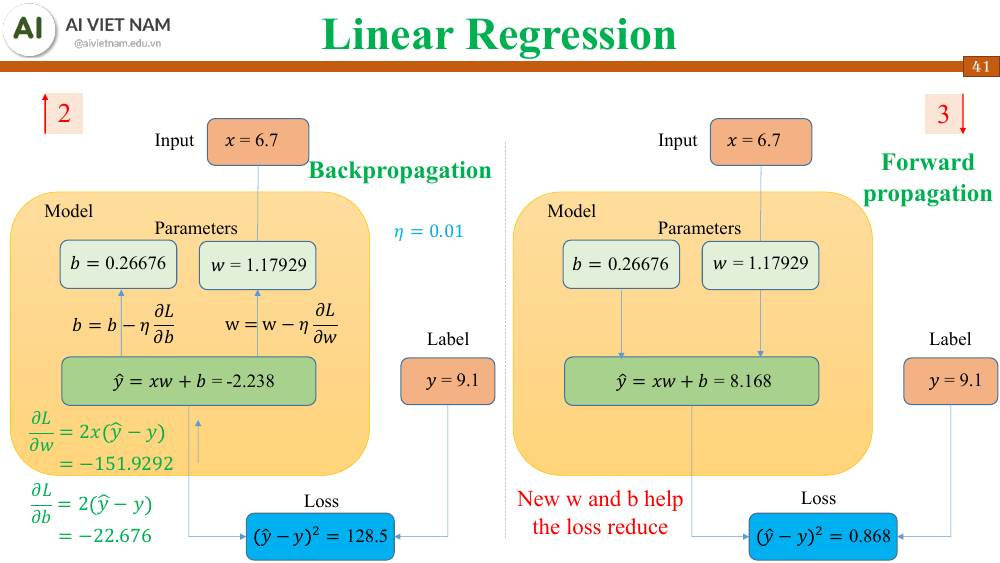<br/><sub><i>Slide trang 42 - Backpropagation + Forward propagation lần 2</i></sub></p>

In [ ]:
dw = 2 * x * (y_hat - y)
db = 2 * (y_hat - y)
print(f"dL/dw = {dw:.4f}   dL/db = {db:.3f}")          # -151.9292 ; -22.676

w_new = w - lr * dw
b_new = b - lr * db
print(f"w = {w_new:.5f}   b = {b_new:.5f}")             # 1.17929 ; 0.26676

# ③ Forward propagation với w, b mới → loss giảm
y_hat_new = x * w_new + b_new
loss_new = (y_hat_new - y) ** 2
print(f"y_hat = {y_hat_new:.3f}   loss = {loss_new:.3f}")   # 8.168 ; 0.868

dL/dw = -151.9292   dL/db = -22.676
w = 1.17929   b = 0.26676
y_hat = 8.168   loss = 0.869


<p align="center">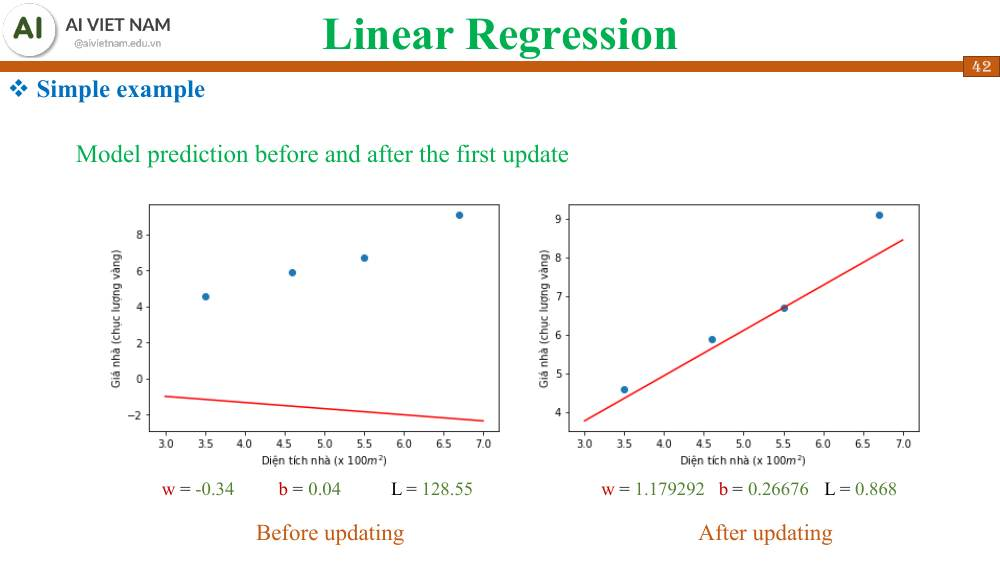<br/><sub><i>Slide trang 43 - Model prediction before and after the first update</i></sub></p>

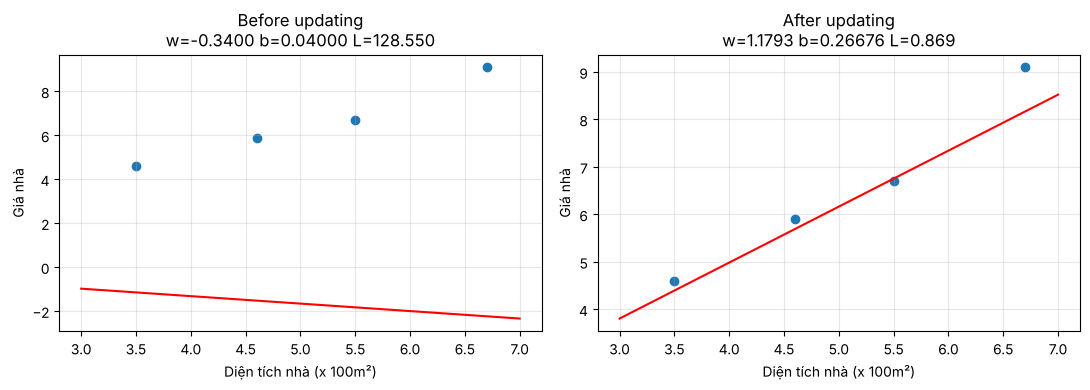

In [ ]:
xs = np.linspace(3, 7, 50)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for a, (ww, bb, L, title) in zip(ax, [(w, b, loss, "Before updating"),
                                       (w_new, b_new, loss_new, "After updating")]):
    a.scatter(areas, prices)
    a.plot(xs, ww * xs + bb, "r")
    a.set_title(f"{title}\nw={ww:.4f} b={bb:.5f} L={L:.3f}")
    a.set_xlabel("Diện tích nhà (x 100m²)"); a.set_ylabel("Giá nhà")
plt.tight_layout(); plt.show()

### Tóm tắt thuật toán (simple version)

1. Pick a sample $(x,y)$ from training data
2. Compute output $\hat y=wx+b$
3. Compute loss $L=(\hat y-y)^2$
4. Compute derivative $\frac{\partial L}{\partial w}=2x(\hat y-y),\;\frac{\partial L}{\partial b}=2(\hat y-y)$
5. Update parameters $w=w-\eta\frac{\partial L}{\partial w},\; b=b-\eta\frac{\partial L}{\partial b}$

<p align="center">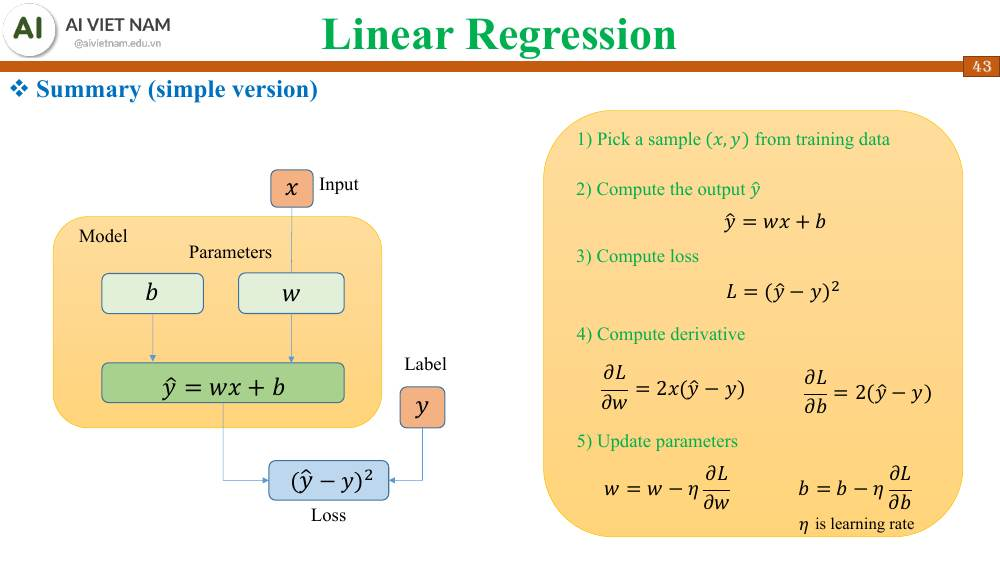<br/><sub><i>Slide trang 44 - Summary (simple version)</i></sub></p>

## 2.5 Implementation — One-sample training

Mỗi lần huấn luyện **một mẫu** (stochastic): cứ mỗi mẫu thì cập nhật `w`, `b` ngay.

**Chuẩn bị dữ liệu** (cột 0 = `area`, cột 1 = `price`):

<p align="center">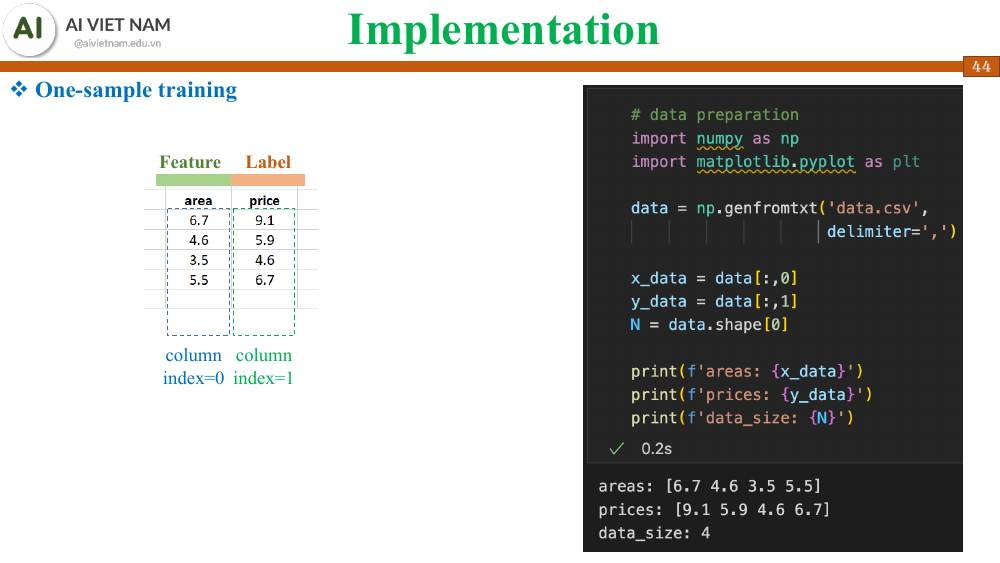<br/><sub><i>Slide trang 45 - Data preparation</i></sub></p>

In [ ]:
# data preparation
data = np.genfromtxt("data.csv", delimiter=",")

x_data = data[:, 0]
y_data = data[:, 1]
N = data.shape[0]

print(f"areas: {x_data}")
print(f"prices: {y_data}")
print(f"data_size: {N}")

areas: [6.7 4.6 3.5 5.5]
prices: [9.1 5.9 4.6 6.7]
data_size: 4


**Các hàm cần thiết:** `predict` (forward), `gradient`, `update_weight`.

<p align="center">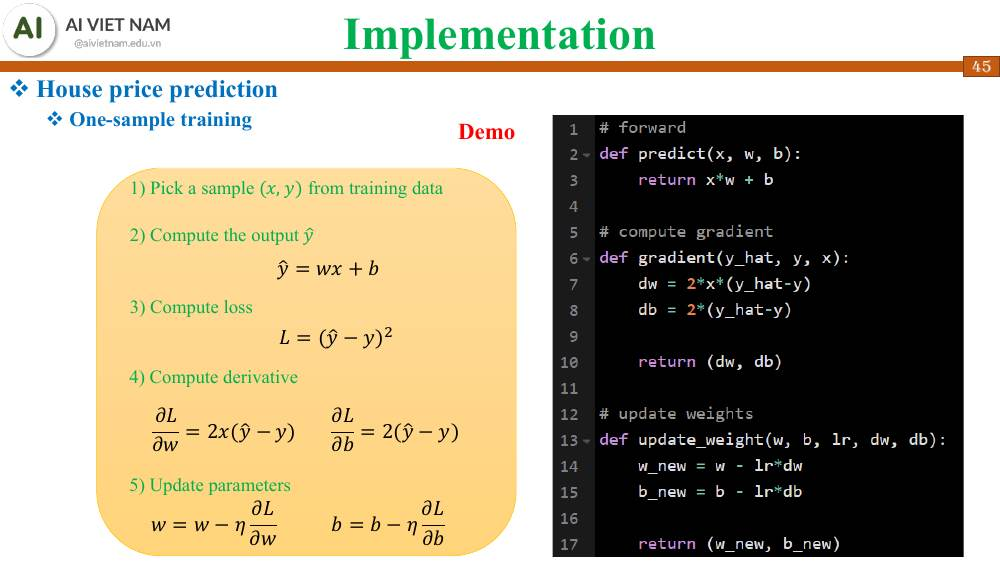<br/><sub><i>Slide trang 46 - House price prediction: predict / gradient / update_weight</i></sub></p>

In [ ]:
# forward
def predict(x, w, b):
    return x * w + b

# compute gradient
def gradient(y_hat, y, x):
    dw = 2 * x * (y_hat - y)
    db = 2 * (y_hat - y)
    return (dw, db)

# update weights
def update_weight(w, b, lr, dw, db):
    w_new = w - lr * dw
    b_new = b - lr * db
    return (w_new, b_new)

**Vòng lặp huấn luyện:** Initialize $w,b$ → Pick sample → Compute output → Compute loss → Compute derivative → Update → lặp lại.

<p align="center">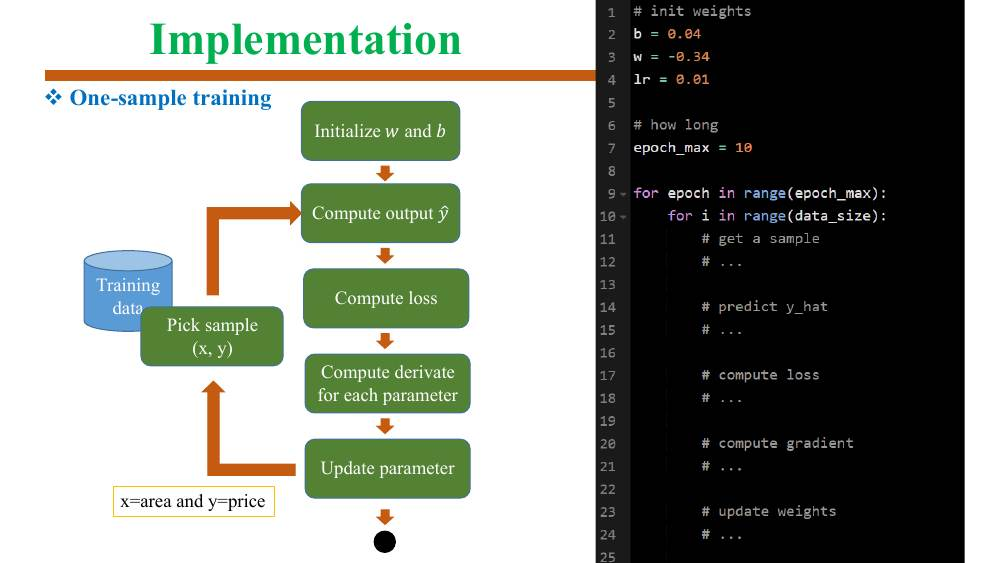<br/><sub><i>Slide trang 47 - One-sample training: sơ đồ khối</i></sub></p>

<p align="center">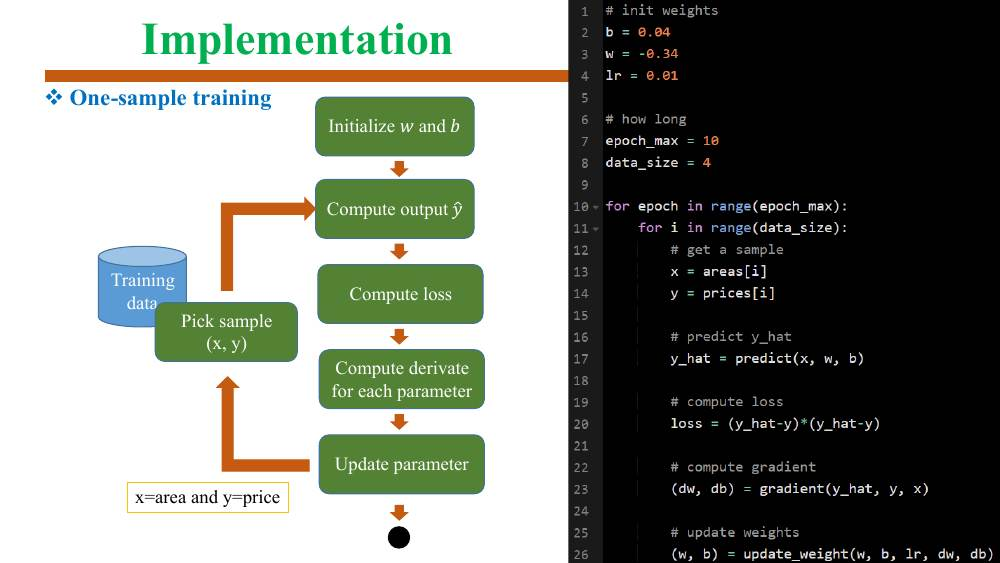<br/><sub><i>Slide trang 48 - One-sample training: code vòng lặp</i></sub></p>

In [ ]:
# init weights
b = 0.04
w = -0.34
lr = 0.01

# how long
epoch_max = 10
data_size = 4
areas, prices = x_data, y_data

losses = []
for epoch in range(epoch_max):
    for i in range(data_size):
        # get a sample
        x = areas[i]
        y = prices[i]

        # predict y_hat
        y_hat = predict(x, w, b)

        # compute loss
        loss = (y_hat - y) * (y_hat - y)
        losses.append(loss)

        # compute gradient
        (dw, db) = gradient(y_hat, y, x)

        # update weights
        (w, b) = update_weight(w, b, lr, dw, db)

print(f"w = {w:.4f}, b = {b:.4f}")

w = 1.2126, b = 0.2252


<p align="center">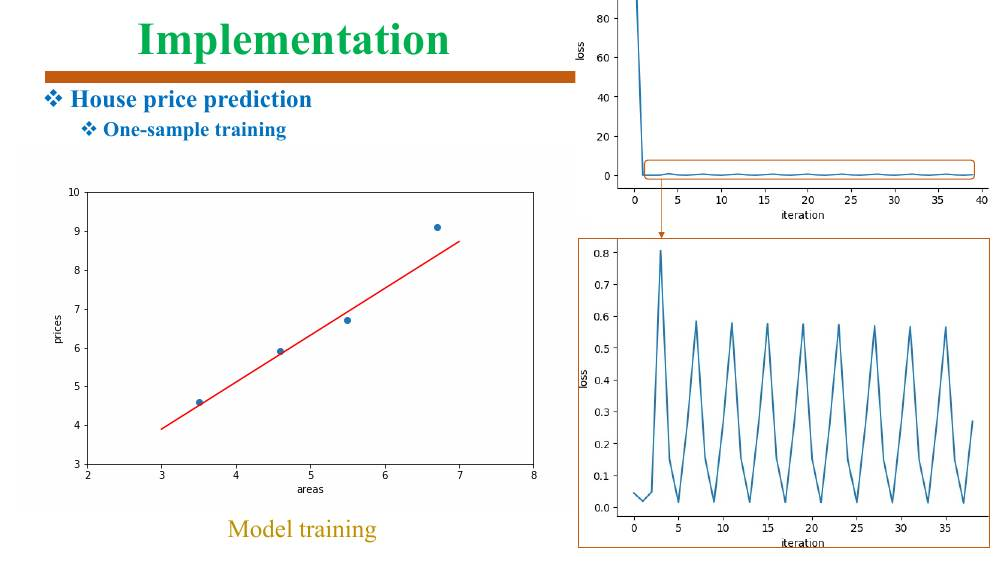<br/><sub><i>Slide trang 49 - Model training</i></sub></p>

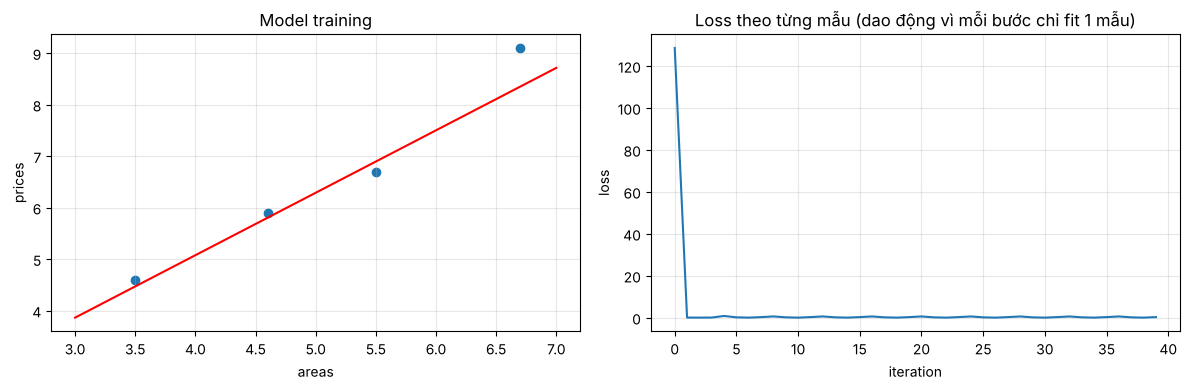

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

xs = np.linspace(3, 7, 50)
ax[0].scatter(areas, prices)
ax[0].plot(xs, w * xs + b, "r")
ax[0].set_xlabel("areas"); ax[0].set_ylabel("prices"); ax[0].set_title("Model training")

ax[1].plot(losses)
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("loss")
ax[1].set_title("Loss theo từng mẫu (dao động vì mỗi bước chỉ fit 1 mẫu)")
plt.tight_layout(); plt.show()

In [ ]:
# Kiểm chứng: nghiệm bình phương tối thiểu (closed form) để so sánh với kết quả gradient descent
A = np.stack([areas, np.ones_like(areas)], axis=1)
(w_ls, b_ls), *_ = np.linalg.lstsq(A, prices, rcond=None)
print(f"Least squares : w = {w_ls:.4f}, b = {b_ls:.4f}")
print(f"SGD (10 epoch): w = {w:.4f}, b = {b:.4f}")
print("→ SGD với learning rate cố định, cập nhật theo từng mẫu nên dao động quanh nghiệm tối ưu "
      "(đúng như loss dao động trong hình trên); tăng epoch hoặc giảm lr sẽ tiến gần hơn.")

Least squares : w = 1.3727, b = -0.3914
SGD (10 epoch): w = 1.2126, b = 0.2252
→ SGD với learning rate cố định, cập nhật theo từng mẫu nên dao động quanh nghiệm tối ưu (đúng như loss dao động trong hình trên); tăng epoch hoặc giảm lr sẽ tiến gần hơn.


## 2.6 General formula — nhiều feature

Với nhiều feature, mô hình là tổ hợp tuyến tính:

- House price: $\hat y=w_1x_1+b$  (`price = w1 * area + b`)
- Advertising: $\hat y=w_1x_1+w_2x_2+w_3x_3+b$  (`Sales = w1*TV + w2*Radio + w3*Newspaper + b`)

<p align="center">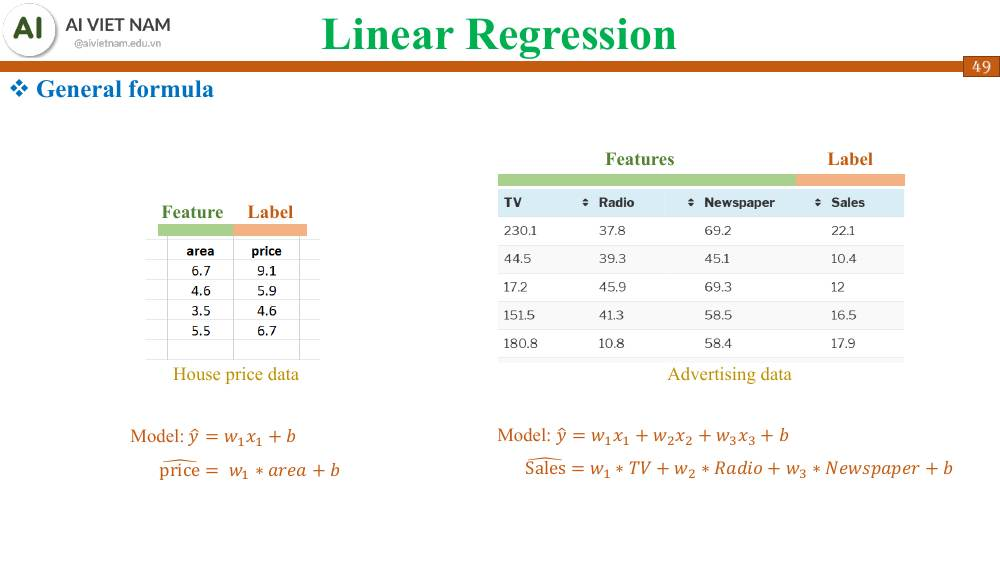<br/><sub><i>Slide trang 50 - General formula</i></sub></p>

**Các bước với 3 feature** $(x_1,x_2,x_3,y)$:

$$\hat y=w_1x_1+w_2x_2+w_3x_3+b,\quad L=(\hat y-y)^2$$

$$\frac{\partial L}{\partial w_1}=2x_1(\hat y-y),\;\frac{\partial L}{\partial w_2}=2x_2(\hat y-y),\;\frac{\partial L}{\partial w_3}=2x_3(\hat y-y),\;\frac{\partial L}{\partial b}=2(\hat y-y)$$

<p align="center">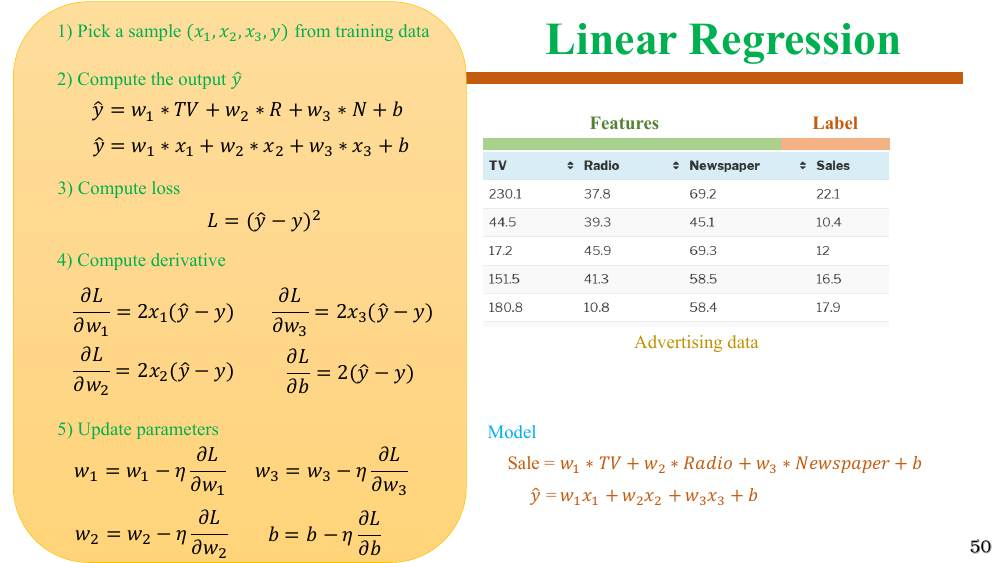<br/><sub><i>Slide trang 51 - Linear Regression với 3 features</i></sub></p>

In [ ]:
# Advertising data (5 dòng đầu như slide): TV, Radio, Newspaper → Sales
adv = np.array([
    [230.1, 37.8, 69.2, 22.1],
    [ 44.5, 39.3, 45.1, 10.4],
    [ 17.2, 45.9, 69.3, 12.0],
    [151.5, 41.3, 58.5, 16.5],
    [180.8, 10.8, 58.4, 17.9],
])

# Một bước cập nhật viết "thủ công" theo công thức trong slide
x1, x2, x3, y = adv[0]
w1 = w2 = w3 = 0.1
b = 0.0
lr = 1e-5       # feature TV ~ hàng trăm nên cần lr rất nhỏ

y_hat = w1 * x1 + w2 * x2 + w3 * x3 + b
loss = (y_hat - y) ** 2

dw1, dw2, dw3 = 2 * x1 * (y_hat - y), 2 * x2 * (y_hat - y), 2 * x3 * (y_hat - y)
db = 2 * (y_hat - y)

w1, w2, w3 = w1 - lr * dw1, w2 - lr * dw2, w3 - lr * dw3
b = b - lr * db
print(f"y_hat={y_hat:.3f} loss={loss:.3f}")
print("grads :", dw1, dw2, dw3, db)
print("params:", w1, w2, w3, b)

y_hat=33.710 loss=134.792
grads : 5342.922 877.7159999999999 1606.824 23.22
params: 0.046570780000000006 0.09122284 0.08393176000000001 -0.0002322


Viết từng đạo hàm riêng như trên rất dài khi số feature tăng → cần **vectorization** (Section 3).

---
# SECTION 3 — Vectorization
## 3.1 Kiến thức nền: Transpose và Broadcasting

- **Transpose:** $\vec v=[v_1,\dots,v_n]^T \to \vec v^T=[v_1\;\dots\;v_n]$; ma trận $A \to A^T$ hoán đổi hàng và cột.
- **Nhân với một số (broadcasting):** $\alpha\vec u=[\alpha u_1,\dots,\alpha u_n]^T$

<p align="center">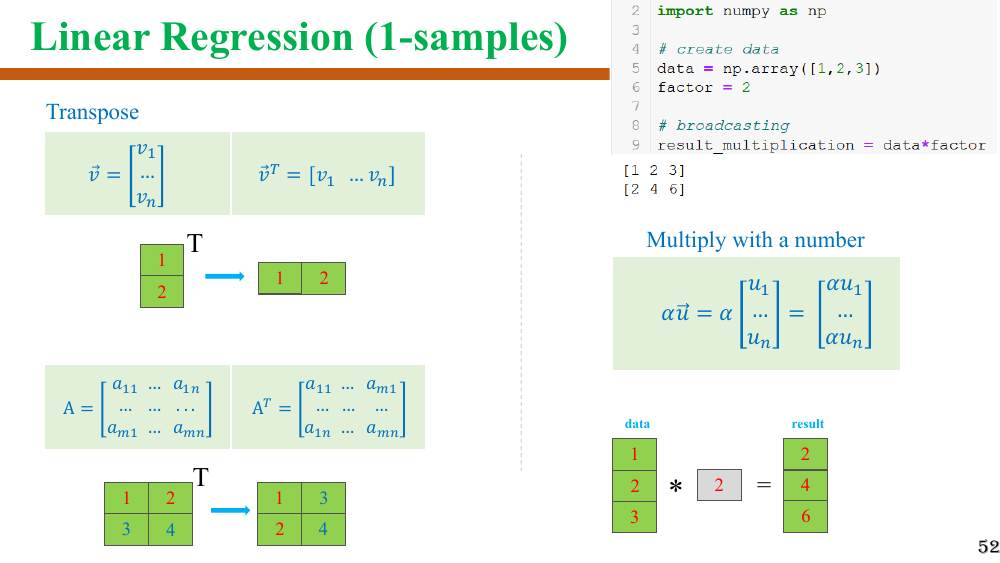<br/><sub><i>Slide trang 54 - Linear Regression (1-samples): Transpose, Multiply with a number</i></sub></p>

In [ ]:
# create data
data_arr = np.array([1, 2, 3])
factor = 2

# broadcasting
result_multiplication = data_arr * factor
print(data_arr)
print(result_multiplication)       # [2 4 6]

# transpose
v = np.array([[1], [2]])
print("v.T =", v.T)

A = np.array([[1, 2], [3, 4]])
print("A.T =\n", A.T)

[1 2 3]
[2 4 6]
v.T = [[1 2]]
A.T =
 [[1 3]
 [2 4]]


## 3.2 Gom tham số vào vector

Đặt

$$\hat y=wx+b,\qquad \boldsymbol x=\begin{bmatrix}1\\x\end{bmatrix},\qquad \boldsymbol\theta=\begin{bmatrix}b\\w\end{bmatrix}\;\Rightarrow\;\boldsymbol\theta^T=[b\;\;w]$$

thì $\hat y = wx+b\cdot 1=[b\;\;w]\begin{bmatrix}1\\x\end{bmatrix}=\boldsymbol\theta^T\boldsymbol x$ — một **dot product**.

Loss $L(\hat y,y)=(\hat y-y)^2$ chỉ làm việc với các **con số** nên giữ nguyên.

<p align="center">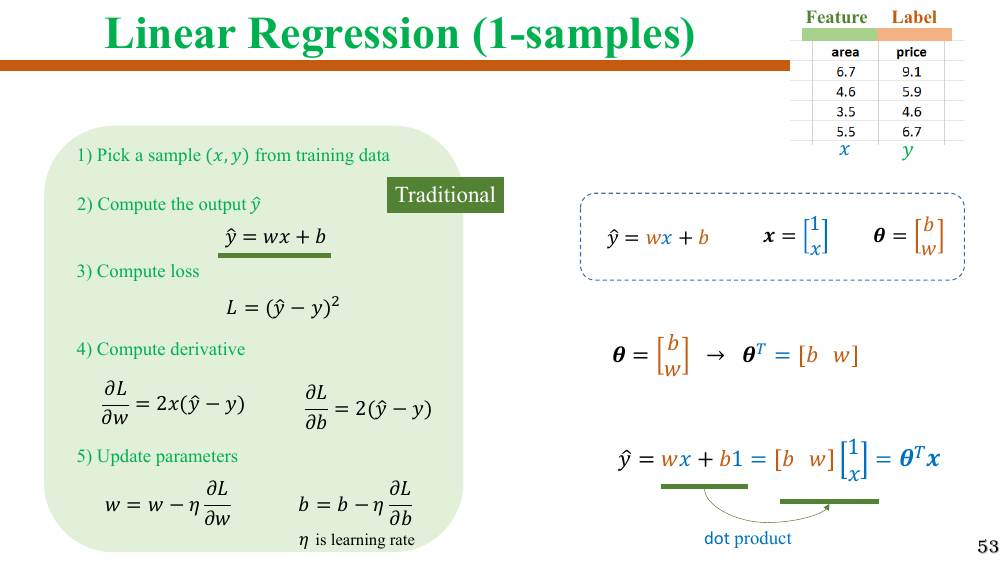<br/><sub><i>Slide trang 55 - Từ ŷ = wx + b đến ŷ = θᵀx</i></sub></p>

<p align="center">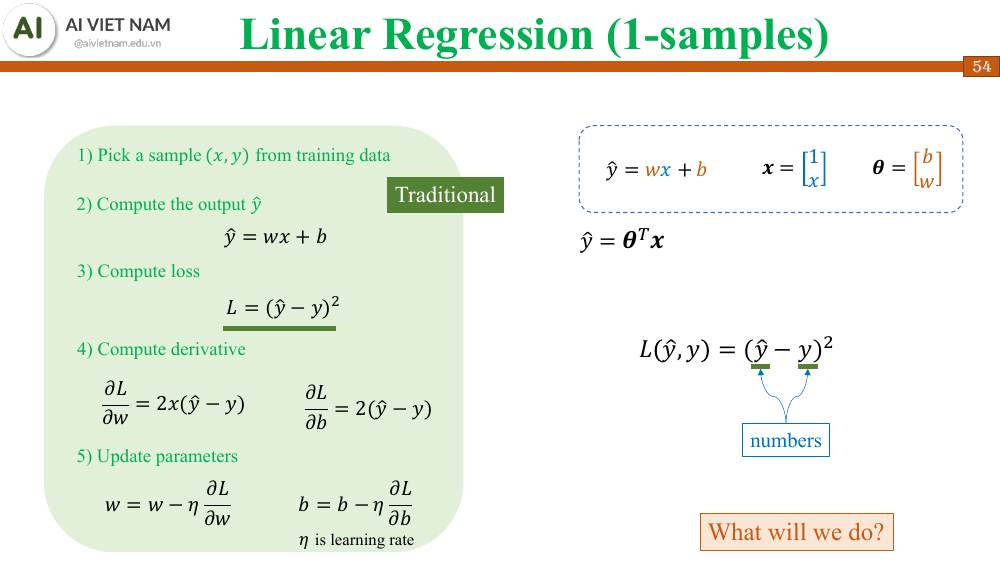<br/><sub><i>Slide trang 56 - Loss chỉ dùng số → What will we do?</i></sub></p>

In [ ]:
theta = np.array([0.049, -0.34])     # [b, w]
x_vec = np.array([1.0, 6.7])         # [1, x]

y_hat = theta.T.dot(x_vec)           # θᵀx
print("y_hat =", y_hat)
assert np.isclose(y_hat, x_vec.dot(theta))     # θᵀx = xᵀθ

y_hat = -2.229


## 3.3 Đạo hàm theo vector — gradient $\nabla_{\boldsymbol\theta}L$

Cả hai đạo hàm riêng có chung thừa số $2(\hat y-y)$:

$$\frac{\partial L}{\partial b}=2(\hat y-y)\times 1,\qquad \frac{\partial L}{\partial w}=2(\hat y-y)\times x
\;\Rightarrow\;
\nabla_{\boldsymbol\theta}L=\begin{bmatrix}\partial L/\partial b\\ \partial L/\partial w\end{bmatrix}=2(\hat y-y)\begin{bmatrix}1\\x\end{bmatrix}=2\boldsymbol x(\hat y-y)$$

<p align="center">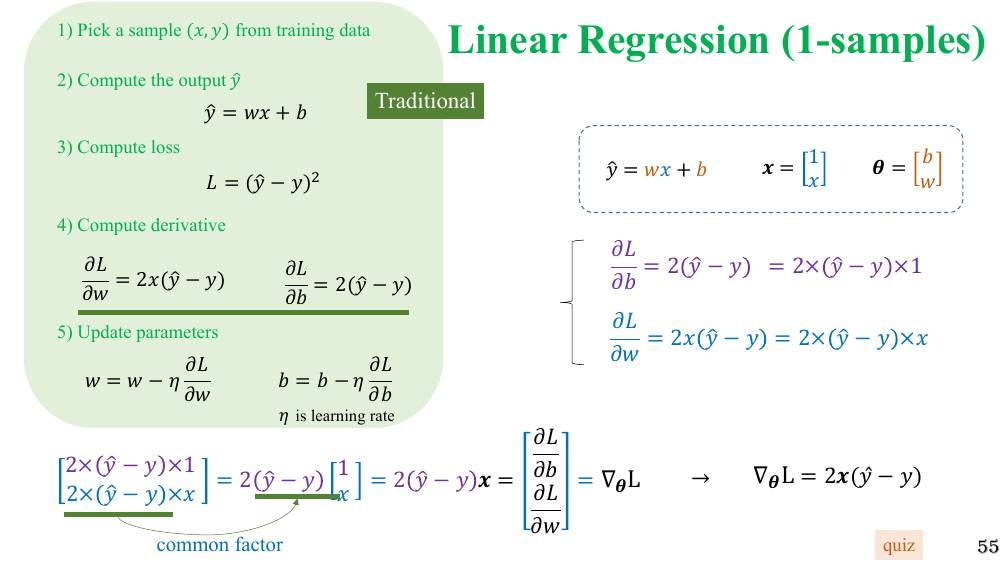<br/><sub><i>Slide trang 57 - Common factor 2(ŷ - y)</i></sub></p>

Cập nhật tham số cũng gộp lại:

$$b=b-\eta\frac{\partial L}{\partial b},\; w=w-\eta\frac{\partial L}{\partial w}\;\Longrightarrow\;\boldsymbol\theta=\boldsymbol\theta-\eta\nabla_{\boldsymbol\theta}L$$

<p align="center">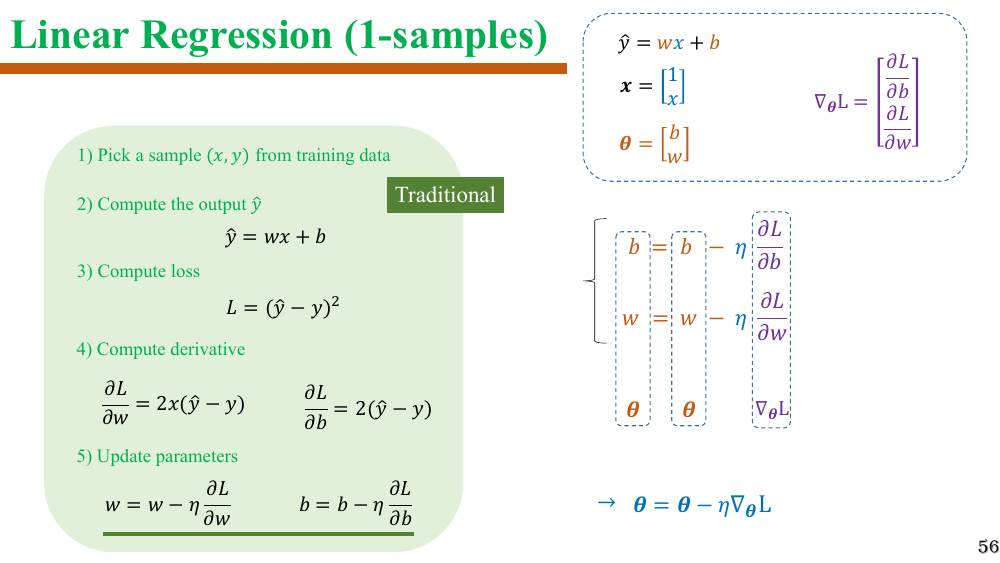<br/><sub><i>Slide trang 58 - θ = θ - η∇θL</i></sub></p>

## 3.4 Traditional vs Vectorized

| Bước | Traditional | Vectorized |
|---|---|---|
| Output | $\hat y=wx+b$ | $\hat y=\boldsymbol\theta^T\boldsymbol x=\boldsymbol x^T\boldsymbol\theta$ |
| Loss | $(\hat y-y)^2$ | $(\hat y-y)^2$ |
| Derivative | $\frac{\partial L}{\partial w}=2x(\hat y-y),\frac{\partial L}{\partial b}=2(\hat y-y)$ | $\nabla_{\boldsymbol\theta}L=2\boldsymbol x(\hat y-y)$ |
| Update | $w=w-\eta\frac{\partial L}{\partial w},\;b=b-\eta\frac{\partial L}{\partial b}$ | $\boldsymbol\theta=\boldsymbol\theta-\eta\nabla_{\boldsymbol\theta}L$ |

<p align="center">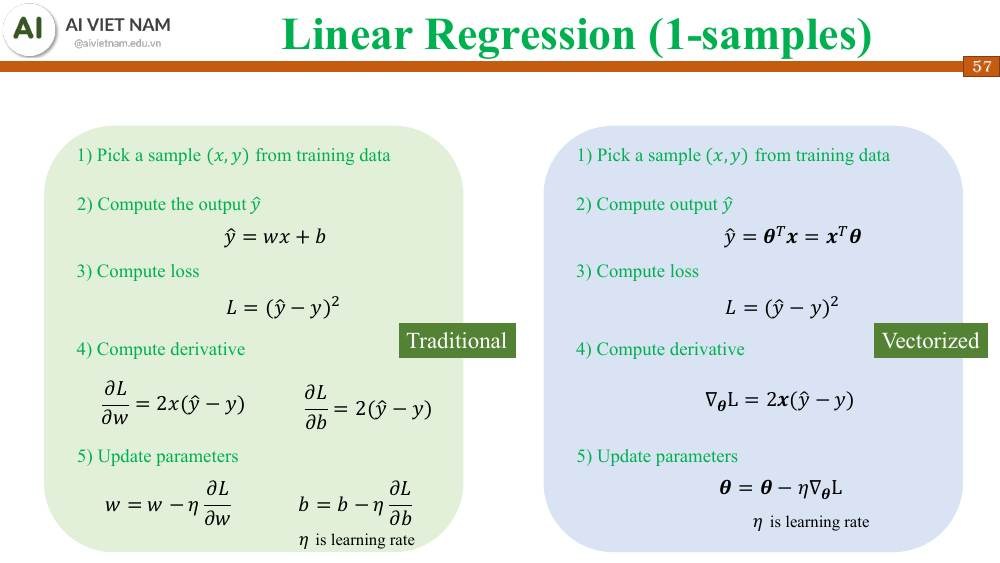<br/><sub><i>Slide trang 59 - Traditional vs Vectorized</i></sub></p>

## 3.5 Ví dụ chạy tay (vectorized)

Mẫu $(6.7,\,9.1)$, $\boldsymbol\theta=[0.049,\,-0.34]^T$, $\eta=0.01$:

<p align="center">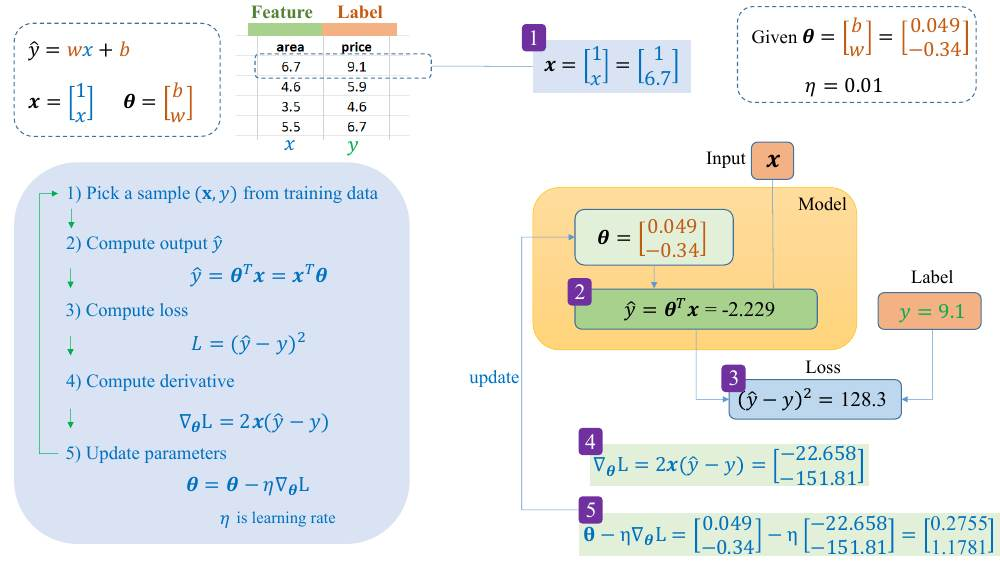<br/><sub><i>Slide trang 60 - Vectorized worked example</i></sub></p>

In [ ]:
theta = np.array([0.049, -0.34])
x_vec = np.array([1.0, 6.7])
y = 9.1
lr = 0.01

y_hat = theta.dot(x_vec)                      # -2.229
loss = (y_hat - y) ** 2                       # 128.3
grad = 2 * x_vec * (y_hat - y)                # [-22.658, -151.81]
theta_new = theta - lr * grad                 # [0.2755, 1.1781]

print("y_hat     =", round(y_hat, 3))
print("loss      =", round(loss, 1))
print("∇θL       =", grad)
print("θ (mới)   =", theta_new)

y_hat     = -2.229
loss      = 128.3
∇θL       = [ -22.658  -151.8086]
θ (mới)   = [0.2756 1.1781]


**Bài tập trong slide** (điền dấu `?`): mẫu $(3.5,\,4.6)$, $\boldsymbol\theta=[0.2,\,0.4]^T$, $\eta=0.01$.

<p align="center">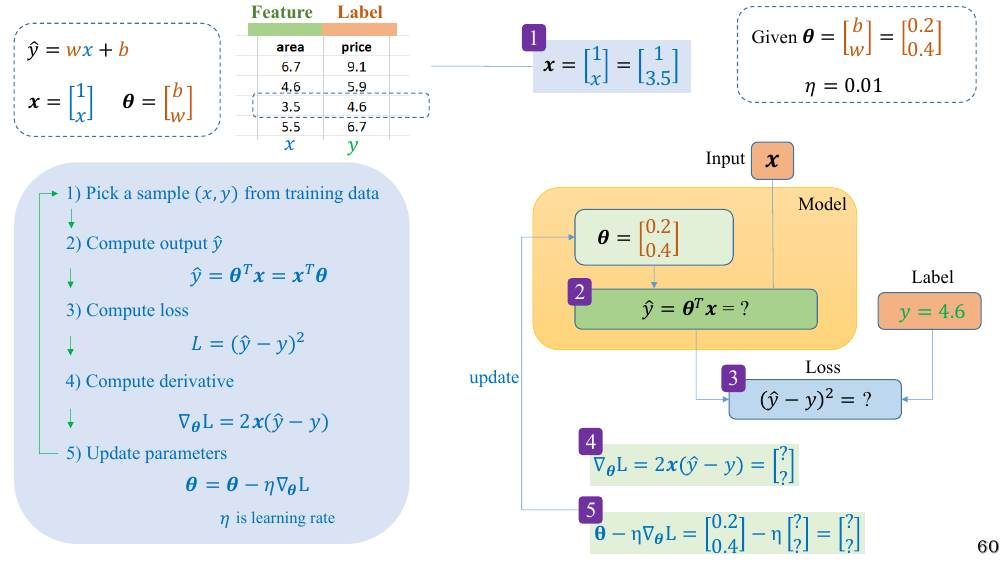<br/><sub><i>Slide trang 62 - Exercise</i></sub></p>

In [ ]:
theta = np.array([0.2, 0.4])
x_vec = np.array([1.0, 3.5])
y = 4.6
lr = 0.01

y_hat = theta.dot(x_vec)
loss = (y_hat - y) ** 2
grad = 2 * x_vec * (y_hat - y)
theta_new = theta - lr * grad

print("y_hat     =", y_hat)       # 1.6
print("loss      =", loss)        # 9.0
print("∇θL       =", grad)        # [-6. -21.]
print("θ (mới)   =", theta_new)   # [0.26 0.61]

y_hat     = 1.6
loss      = 8.999999999999998
∇θL       = [ -6. -21.]
θ (mới)   = [0.26 0.61]


## 3.6 Implementation — vectorization với NumPy

<p align="center">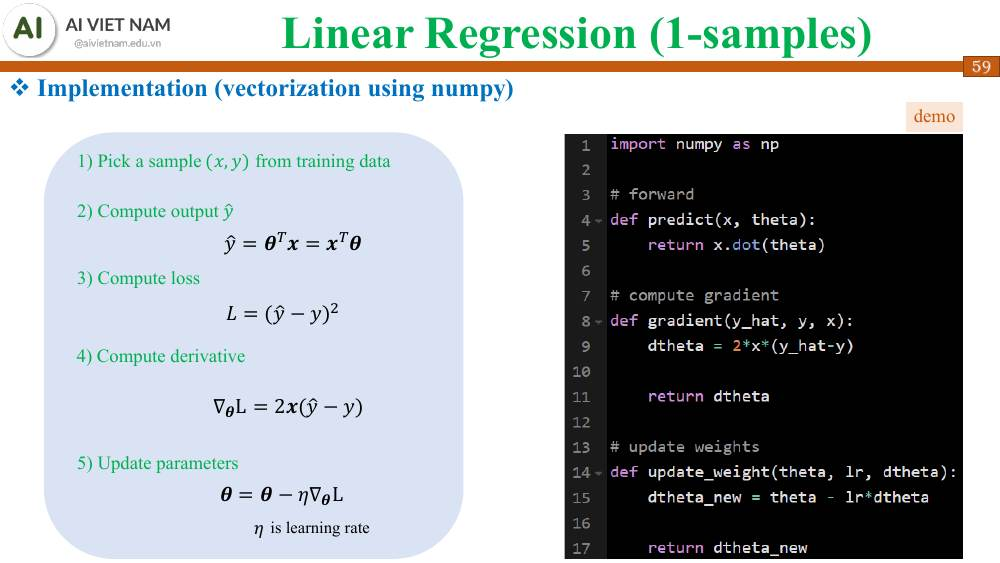<br/><sub><i>Slide trang 61 - Implementation (vectorization using numpy)</i></sub></p>

<p align="center">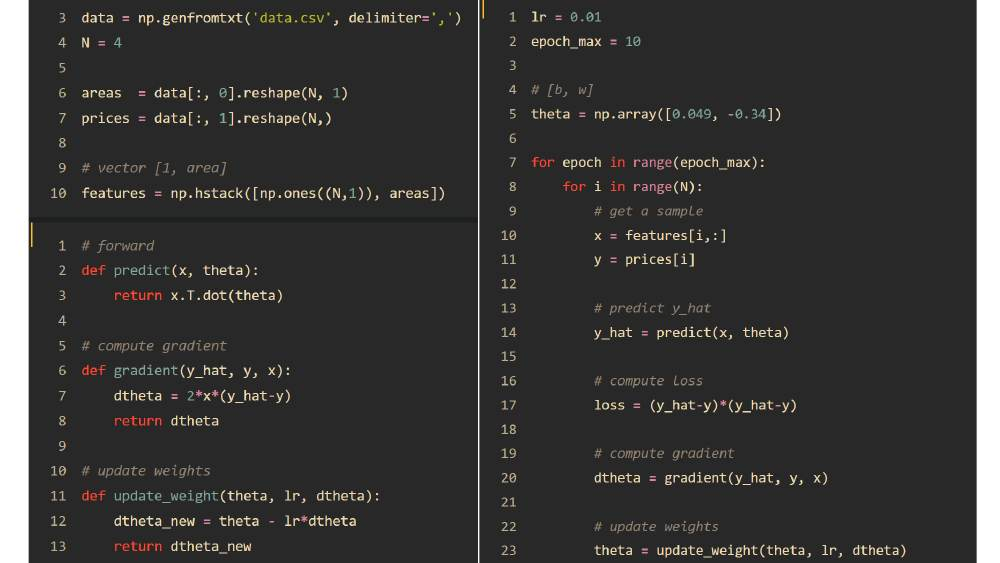<br/><sub><i>Slide trang 63 - Code vectorized (one-sample training)</i></sub></p>

In [ ]:
# forward
def predict(x, theta):
    return x.T.dot(theta)

# compute gradient
def gradient(y_hat, y, x):
    dtheta = 2 * x * (y_hat - y)
    return dtheta

# update weights
def update_weight(theta, lr, dtheta):
    dtheta_new = theta - lr * dtheta
    return dtheta_new

In [ ]:
data = np.genfromtxt("data.csv", delimiter=",")
N = 4

areas  = data[:, 0].reshape(N, 1)
prices = data[:, 1].reshape(N,)

# vector [1, area]
features = np.hstack([np.ones((N, 1)), areas])
print(features)

[[1.  6.7]
 [1.  4.6]
 [1.  3.5]
 [1.  5.5]]


In [ ]:
lr = 0.01
epoch_max = 10

# [b, w]
theta = np.array([0.049, -0.34])
losses = []

for epoch in range(epoch_max):
    for i in range(N):
        # get a sample
        x = features[i, :]
        y = prices[i]

        # predict y_hat
        y_hat = predict(x, theta)

        # compute loss
        loss = (y_hat - y) * (y_hat - y)
        losses.append(loss)

        # compute gradient
        dtheta = gradient(y_hat, y, x)

        # update weights
        theta = update_weight(theta, lr, dtheta)

print("theta [b, w] =", theta)

theta [b, w] = [0.2335 1.211 ]


In [ ]:
# Đối chiếu với bản "traditional" (b=0.04, w=-0.34 ban đầu) — hai cách phải cho cùng kết quả
def train_traditional(b, w, lr, epochs, X, Y):
    for _ in range(epochs):
        for x, y in zip(X, Y):
            y_hat = x * w + b
            w, b = w - lr * 2 * x * (y_hat - y), b - lr * 2 * (y_hat - y)
    return b, w

def train_vectorized(theta, lr, epochs, F, Y):
    for _ in range(epochs):
        for x, y in zip(F, Y):
            theta = theta - lr * 2 * x * (x.dot(theta) - y)
    return theta

b_t, w_t = train_traditional(0.04, -0.34, 0.01, 10, data[:, 0], data[:, 1])
th_v = train_vectorized(np.array([0.04, -0.34]), 0.01, 10, features, prices)
print("traditional [b, w] =", np.array([b_t, w_t]))
print("vectorized  [b, w] =", th_v)
assert np.allclose([b_t, w_t], th_v)
print("Hai cách cho cùng kết quả ✔")

traditional [b, w] = [0.2252 1.2126]
vectorized  [b, w] = [0.2252 1.2126]
Hai cách cho cùng kết quả ✔


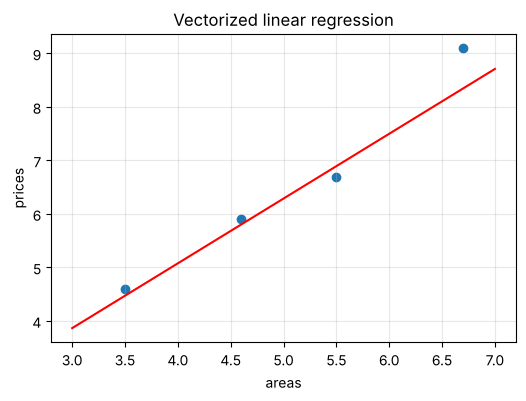

In [ ]:
xs = np.linspace(3, 7, 50)
plt.scatter(areas, prices)
plt.plot(xs, theta[0] + theta[1] * xs, "r")
plt.xlabel("areas"); plt.ylabel("prices"); plt.title("Vectorized linear regression")
plt.show()

## 3.7 Advertising Problem (3 features) bằng vectorization

$$\hat y=w_1x_1+w_2x_2+w_3x_3+b,\qquad
\boldsymbol x=\begin{bmatrix}1\\x_1\\x_2\\x_3\end{bmatrix},\;
\boldsymbol\theta=\begin{bmatrix}b\\w_1\\w_2\\w_3\end{bmatrix}$$

Code **không cần thay đổi** so với trường hợp 1 feature — chỉ cần `x` và `theta` dài hơn. Đó là sức mạnh của vectorization.

Bài hỏi: *nếu TV=55.0, Radio=34.0, Newspaper=62.0 thì Sales=?*

<p align="center">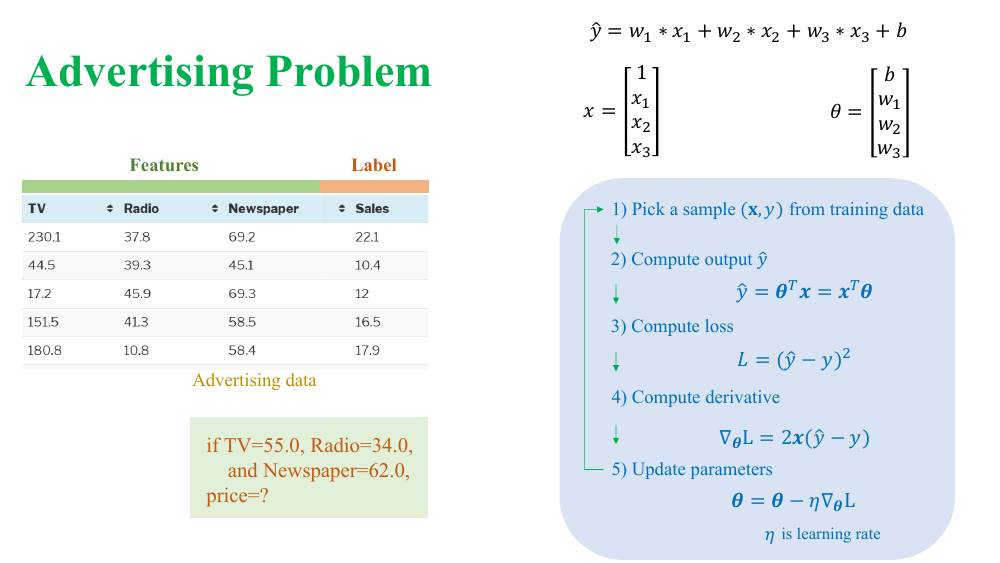<br/><sub><i>Slide trang 64 - Advertising Problem</i></sub></p>

In [ ]:
# Dùng lại các hàm predict / gradient / update_weight ở trên.
# Chỉ có 5 dòng dữ liệu trong slide nên kết quả chỉ mang tính minh họa.
# (Bộ Advertising đầy đủ có 200 dòng - bạn có thể thay `adv` bằng np.genfromtxt('Advertising.csv', ...))
X_raw = adv[:, :3]
Y_adv = adv[:, 3]

# Chuẩn hóa feature (z-score) để các feature cùng thang đo → dùng được learning rate lớn hơn
mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
X_std = (X_raw - mu) / sigma
F = np.hstack([np.ones((len(X_std), 1)), X_std])        # [1, x1, x2, x3]

theta = np.zeros(4)                                     # [b, w1, w2, w3]
lr, epochs = 0.02, 500
for epoch in range(epochs):
    for x, y in zip(F, Y_adv):
        y_hat = predict(x, theta)
        theta = update_weight(theta, lr, gradient(y_hat, y, x))

print("theta [b, w1, w2, w3] (trên feature đã chuẩn hóa) =", theta)

# Dự đoán cho TV=55, Radio=34, Newspaper=62
x_new = np.array([55.0, 34.0, 62.0])
x_new_vec = np.concatenate([[1.0], (x_new - mu) / sigma])
print("Dự đoán Sales =", round(float(predict(x_new_vec, theta)), 2))

theta [b, w1, w2, w3] (trên feature đã chuẩn hóa) = [15.775   3.785   0.1222  1.1021]
Dự đoán Sales = 12.74


---
# Tổng kết

- **Gradient descent:** $x_{new}=x_{old}-\eta\frac{d}{dx}J(x_{old})$ — đi ngược chiều đạo hàm; với hàm nhiều biến/hàm hợp dùng đạo hàm riêng + chain rule.
- **Linear Regression:** Initialize $w,b$ → pick sample $(x,y)$ → compute output $\hat y$ → compute loss → compute derivative cho từng tham số → update parameters → lặp lại.
- **Vectorization:** gom tham số vào $\boldsymbol\theta$ → $\boldsymbol\theta=\boldsymbol\theta-\eta\nabla_{\boldsymbol\theta}L$, áp dụng được cho bất kỳ số feature nào.

<p align="center">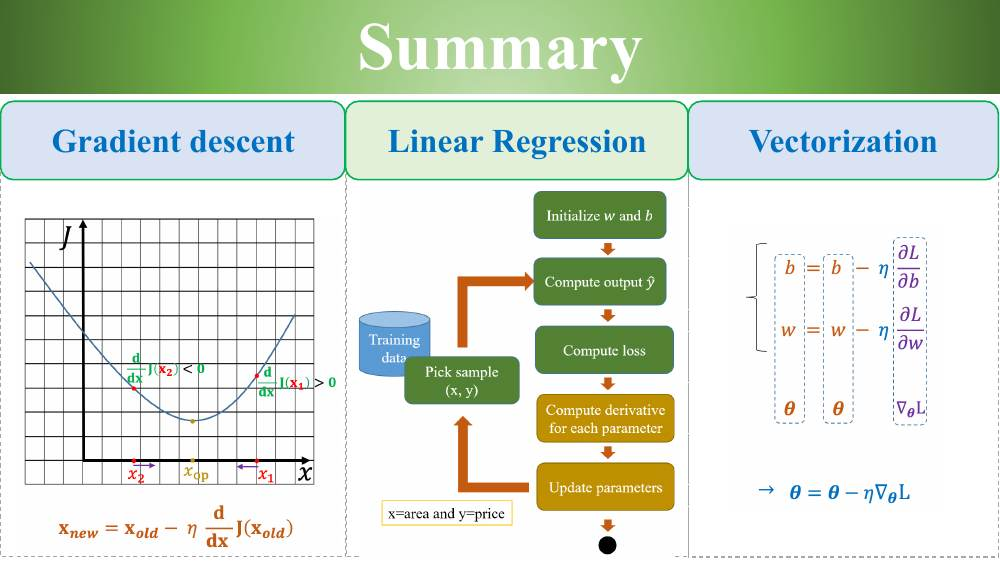<br/><sub><i>Slide trang 65 - Summary</i></sub></p>